a histogram gradient-boosting regressor with a log-transformed target. The model can learn a curved distance-to-duration relationship while the monotonic constraint prevents predicted duration from falling as distance increases.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

RANDOM_STATE = 42
pd.set_option("display.max_columns", 80)

### Find the project data
The expected input is data/processed/tour_level/retained_tours_quality_checked.csv. The path search works when this notebook is opened from the repository or its notebooks folder.

In [2]:
DATA_RELATIVE_PATH = Path(
    "data/processed/tour_level/retained_tours_quality_checked.csv"
)

cwd = Path.cwd().resolve()
candidate_roots = list(dict.fromkeys([
    cwd,
    *cwd.parents,
    Path.home() / "Desktop" / "dt-cargo-vehicle-telemetry-",
]))

PROJECT_ROOT = next(
    (
        root for root in candidate_roots
        if (root / DATA_RELATIVE_PATH).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not find {DATA_RELATIVE_PATH}. "
        "Set PROJECT_ROOT to the local repository folder."
    )

DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
print("Project root:", PROJECT_ROOT)
print("Tour data:", DATA_PATH)

Project root: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-
Tour data: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-/data/processed/tour_level/retained_tours_quality_checked.csv


### Load the tour-level table and check its schema
The tour table should have one row per vehicle-tour pair. We check the columns needed for the target, feature, time split, and quality rule before modeling.

In [3]:
tours = pd.read_csv(DATA_PATH)

required_columns = [
    "vehicle_id",
    "tour_id",
    "start_time",
    "total_distance_km",
    "elapsed_span_hours",
    "requires_quality_review",
]
missing_columns = [column for column in required_columns if column not in tours.columns]
if missing_columns:
    raise ValueError(f"Missing required tour columns: {missing_columns}")

print("Rows and columns:", tours.shape)
print("Available columns:")
print(tours.columns.tolist())
display(tours.head())

Rows and columns: (13413, 26)
Available columns:
['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review']


,vehicle_id,tour_id,track_count,start_time,last_track_start,end_time,total_distance_km,total_valid_track_duration_seconds,valid_duration_track_count,home_base_endpoint,elapsed_span_hours,recorded_track_hours,distance_based_avg_speed_kmh,fleet_test_id,long_haul,rest_area,service_area_fuel,industrial_area,home_base,cid,negative_elapsed_span,non_positive_distance,duration_incomplete,duration_unusable,high_distance_based_speed,requires_quality_review
0,1,0,3,2021-09-10 09:04:53.598000+00:00,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,57.945,7412.956,3,True,3.082557,2.059154,28.140191,1,False,False,False,True,False,149,False,False,False,False,False,False
1,1,1,7,2021-09-10 12:21:35.547000+00:00,2021-09-13 06:08:10.018000+00:00,2021-09-13 06:08:26.837000+00:00,0.371,763.286,7,True,65.780914,0.212024,1.749803,1,False,False,False,True,True,0,False,False,False,False,False,False
2,1,2,8,2021-09-13 06:25:03.766000+00:00,2021-09-14 11:24:50.310000+00:00,2021-09-14 11:45:39.906000+00:00,36.554,4767.617,8,True,29.343372,1.324338,27.601714,1,False,False,False,True,False,301,False,False,False,False,False,False
3,1,3,104,2021-09-14 11:49:23.603000+00:00,2021-10-07 08:44:23.587000+00:00,2021-10-07 08:49:40.058000+00:00,6.757,17947.817,104,True,549.004571,4.985505,1.355329,1,False,False,False,True,True,0,False,False,False,False,False,False
4,1,4,16,2021-10-07 10:19:52.098000+00:00,2021-10-09 06:35:21.071000+00:00,2021-10-09 07:59:24.414000+00:00,1291.041,74143.179,16,True,45.658977,20.595327,62.686112,1,False,False,False,True,False,149,False,False,False,False,False,False


### Verify the analysis unit
A tour is identified by vehicle_id and tour_id. Duplicate keys would cause multiple rows for one tour to leak across the chronological split, so this notebook stops if the expected one-row-per-tour structure is not present.

In [4]:
TOUR_KEYS = ["vehicle_id", "tour_id"]

missing_key_rows = tours[TOUR_KEYS].isna().any(axis=1)
duplicate_tour_rows = tours.duplicated(subset=TOUR_KEYS, keep=False)

print("Rows with a missing tour key:", int(missing_key_rows.sum()))
print("Rows in duplicated vehicle-tour keys:", int(duplicate_tour_rows.sum()))

if missing_key_rows.any():
    raise ValueError("Resolve missing vehicle_id or tour_id values before modeling.")
if duplicate_tour_rows.any():
    raise ValueError(
        "Expected one row per (vehicle_id, tour_id); duplicate tour rows were found."
    )

Rows with a missing tour key: 0
Rows in duplicated vehicle-tour keys: 0


### Clean target, feature, time, and quality flag
We remove rows that cannot be scored because they lack a valid start time, distance, or positive elapsed-span target. Quality-review tours are retained in the table: the flag controls training eligibility only. Missing or unrecognized quality flags are treated as requiring review.

In [5]:
TARGET = "elapsed_span_hours"
FEATURE = "total_distance_km"
QUALITY_FLAG = "requires_quality_review"

tours["start_time"] = pd.to_datetime(
    tours["start_time"], utc=True, errors="coerce"
)
for column in [FEATURE, TARGET]:
    tours[column] = pd.to_numeric(tours[column], errors="coerce")

tours = tours.replace([np.inf, -np.inf], np.nan)

flag_map = {
    "true": True, "false": False,
    "1": True, "0": False,
    "yes": True, "no": False,
}
parsed_flag = (
    tours[QUALITY_FLAG]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(flag_map)
)
tours[QUALITY_FLAG] = parsed_flag.fillna(True).astype(bool)

rows_before_cleaning = len(tours)
valid_rows = (
    tours["start_time"].notna()
    & tours[FEATURE].notna()
    & tours[TARGET].notna()
    & tours[FEATURE].gt(0)
    & tours[TARGET].gt(0)
)
tours = (
    tours.loc[valid_rows]
    .sort_values("start_time", kind="stable")
    .reset_index(drop=True)
)

print("Rows before cleaning:", rows_before_cleaning)
print("Valid tours retained:", len(tours))
print("Rows removed as unscorable:", rows_before_cleaning - len(tours))
print("Tours requiring quality review:", int(tours[QUALITY_FLAG].sum()))
print("Start-time range:", tours["start_time"].min(), "to", tours["start_time"].max())

Rows before cleaning: 13413
Valid tours retained: 13393
Rows removed as unscorable: 20
Tours requiring quality review: 244
Start-time range: 2021-08-26 13:27:59.533000+00:00 to 2024-01-15 06:11:14.907000+00:00


### Inspect the target and distance
This is a quick data check before fitting. The distance-only model deliberately leaves out IDs, end times, recorded duration, and quality labels. Those fields either identify tours or are only known after the outcome has occurred.

,count,mean,std,min,50%,90%,99%,max
total_distance_km,13393.0,136.07,324.26,0.0,23.03,344.87,1509.00,7714.37
elapsed_span_hours,13393.0,25.81,160.36,0.0,4.40,46.09,269.22,4024.94


,tours
requires_quality_review,
False,13149
True,244


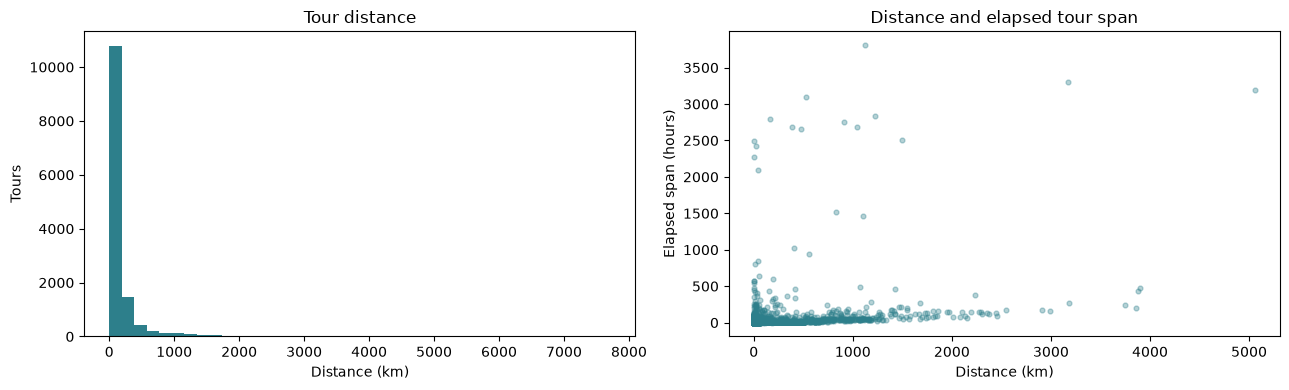

In [6]:
display(
    tours[[FEATURE, TARGET]]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .T
    .round(2)
)

quality_summary = (
    tours[QUALITY_FLAG]
    .value_counts()
    .rename_axis("requires_quality_review")
    .to_frame("tours")
)
display(quality_summary)

plot_data = tours[[FEATURE, TARGET]].copy()
if len(plot_data) > 5000:
    plot_data = plot_data.sample(5000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(tours[FEATURE], bins=40, color="#2d7f8b")
axes[0].set(title="Tour distance", xlabel="Distance (km)", ylabel="Tours")
axes[1].scatter(
    plot_data[FEATURE], plot_data[TARGET],
    s=12, alpha=0.35, color="#2d7f8b",
)
axes[1].set(
    title="Distance and elapsed tour span",
    xlabel="Distance (km)",
    ylabel="Elapsed span (hours)",
)
plt.tight_layout()
plt.show()

### Define the model inputs and chronological holdout
The earliest 80% of tours form the training pool and the latest 20% form the holdout. Only the distance feature is used. Tours requiring quality review are excluded from fitting, but remain in the holdout evaluation when their target and distance are valid.

In [7]:
FEATURES = [FEATURE]
TRAIN_FRACTION = 0.80

split_at = int(TRAIN_FRACTION * len(tours))
training_pool = tours.iloc[:split_at].copy()
later_holdout = tours.iloc[split_at:].copy()

eligible_training = training_pool.loc[
    ~training_pool[QUALITY_FLAG]
].copy()

if len(eligible_training) < 2 or len(later_holdout) < 2:
    raise ValueError("There are not enough tours for training and holdout scoring.")

print("Training-pool tours:", len(training_pool))
print("Unflagged tours used for fitting:", len(eligible_training))
print("Later holdout tours scored:", len(later_holdout))
print(
    "Training-pool dates:",
    training_pool["start_time"].min(), "to", training_pool["start_time"].max()
)
print(
    "Holdout dates:",
    later_holdout["start_time"].min(), "to", later_holdout["start_time"].max()
)

Training-pool tours: 10714
Unflagged tours used for fitting: 10506
Later holdout tours scored: 2679
Training-pool dates: 2021-08-26 13:27:59.533000+00:00 to 2022-03-17 04:21:49.753000+00:00
Holdout dates: 2022-03-17 05:42:14.410000+00:00 to 2024-01-15 06:11:14.907000+00:00


### Build the tour-level regressor
The log transform helps with a right-skewed duration target and makes predictions positive after the inverse transform. The monotonic constraint encodes the reasonable baseline assumption that longer tours should not receive lower predictions when all else is equal.

In [8]:
def build_regressor():
    base_regressor = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=2.0,
        monotonic_cst=[1],
        early_stopping=False,
        random_state=RANDOM_STATE,
    )
    return TransformedTargetRegressor(
        regressor=base_regressor,
        func=np.log1p,
        inverse_func=np.expm1,
    )


def regression_scores(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "R2": r2_score(actual, predicted),
        "MAE_hours": mean_absolute_error(actual, predicted),
        "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
    }


regressor = build_regressor()
print(regressor)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=HistGradientBoostingRegressor(early_stopping=False,
                                                                   l2_regularization=2.0,
                                                                   learning_rate=0.05,
                                                                   max_iter=150,
                                                                   max_leaf_nodes=15,
                                                                   min_samples_leaf=40,
                                                                   monotonic_cst=[1],
                                                                   random_state=42))


### Check stability with five chronological folds
Cross-validation happens inside the first 80% only. Each fold trains on earlier tours and validates on later tours. The quality rule is applied to each fold's training rows only; every valid row in a validation fold is scored.

In [9]:
cv = TimeSeriesSplit(n_splits=5)
fold_rows = []
oof_parts = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(training_pool), start=1
):
    fold_train = training_pool.iloc[train_idx].copy()
    fold_valid = training_pool.iloc[valid_idx].copy()
    fold_train = fold_train.loc[~fold_train[QUALITY_FLAG]]

    if len(fold_train) < 2:
        raise ValueError(f"Fold {fold} has too few eligible training tours.")

    fold_model = build_regressor()
    fold_model.fit(fold_train[FEATURES], fold_train[TARGET])
    prediction = fold_model.predict(fold_valid[FEATURES])

    fold_rows.append({
        "fold": fold,
        "train_tours": len(fold_train),
        "validation_tours": len(fold_valid),
        "validation_start": fold_valid["start_time"].min(),
        "validation_end": fold_valid["start_time"].max(),
        **regression_scores(fold_valid[TARGET], prediction),
    })

    fold_output = fold_valid[
        ["vehicle_id", "tour_id", "start_time", FEATURE, TARGET, QUALITY_FLAG]
    ].copy()
    fold_output["fold"] = fold
    fold_output["prediction_hours"] = prediction
    fold_output["error_hours"] = prediction - fold_output[TARGET]
    fold_output["absolute_error_hours"] = fold_output["error_hours"].abs()
    oof_parts.append(fold_output)

fold_results = pd.DataFrame(fold_rows)
oof_predictions = pd.concat(oof_parts, ignore_index=True)

### Review cross-validation results
R² measures explained variation, while MAE is the typical absolute miss in hours. RMSE gives larger errors more weight. The pooled score combines all chronological out-of-fold predictions

In [10]:
display(fold_results.round(3))

metric_columns = ["R2", "MAE_hours", "RMSE_hours"]
print("Mean across folds:")
display(fold_results[metric_columns].mean().round(3))

print("Fold-to-fold standard deviation:")
display(fold_results[metric_columns].std().round(3))

print("Pooled out-of-fold scores:")
display(
    pd.Series(
        regression_scores(
            oof_predictions[TARGET],
            oof_predictions["prediction_hours"],
        )
    ).round(3)
)

/var/folders/f3/djm8twy54lg9bwn9lkdpg_fh0000gn/T/ipykernel_10438/323088737.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(fold_results.round(3))


,fold,train_tours,validation_tours,validation_start,validation_end,R2,MAE_hours,RMSE_hours
0,1,1755,1785,2021-10-21 07:19:38.200000+00:00,2021-11-24 02:59:29.333000+00:00,0.009,15.366,69.900
1,2,3510,1785,2021-11-24 03:55:27.343000+00:00,2021-12-23 04:00:09.553000+00:00,0.041,17.562,70.595
2,3,5244,1785,2021-12-23 04:04:43.337000+00:00,2022-01-22 23:30:22.981000+00:00,0.058,14.533,51.148
3,4,6991,1785,2022-01-23 08:00:36.161000+00:00,2022-02-15 20:42:55.082000+00:00,0.097,10.594,34.595
4,5,8750,1785,2022-02-15 20:43:22.860000+00:00,2022-03-17 04:21:49.753000+00:00,0.141,9.750,28.613


Mean across folds:


R2             0.069
MAE_hours     13.561
RMSE_hours    50.970
dtype: float64

Fold-to-fold standard deviation:


R2             0.051
MAE_hours      3.299
RMSE_hours    19.439
dtype: float64

Pooled out-of-fold scores:


R2             0.049
MAE_hours     13.561
RMSE_hours    53.854
dtype: float64

### Fit the training-pool model and score the later holdout
The later 20% remains untouched during fitting and cross-validation. A mean-only dummy regressor gives a simple reference point: the tour model should beat this reference to be useful.

In [11]:
final_model = build_regressor()
final_model.fit(eligible_training[FEATURES], eligible_training[TARGET])
holdout_prediction = final_model.predict(later_holdout[FEATURES])

mean_baseline = DummyRegressor(strategy="mean")
mean_baseline.fit(eligible_training[FEATURES], eligible_training[TARGET])
baseline_prediction = mean_baseline.predict(later_holdout[FEATURES])

holdout_predictions = later_holdout[
    ["vehicle_id", "tour_id", "start_time", FEATURE, TARGET, QUALITY_FLAG]
].copy()
holdout_predictions["model_prediction_hours"] = holdout_prediction
holdout_predictions["mean_baseline_hours"] = baseline_prediction
holdout_predictions["error_hours"] = (
    holdout_predictions["model_prediction_hours"] - holdout_predictions[TARGET]
)
holdout_predictions["absolute_error_hours"] = (
    holdout_predictions["error_hours"].abs()
)

holdout_results = pd.DataFrame([
    {
        "model": "Distance-based HGB",
        **regression_scores(later_holdout[TARGET], holdout_prediction),
    },
    {
        "model": "Training mean",
        **regression_scores(later_holdout[TARGET], baseline_prediction),
    },
])
display(holdout_results.round(3))
print("Holdout tours scored:", len(holdout_predictions))
print(
    "Quality-review tours included in holdout:",
    int(holdout_predictions[QUALITY_FLAG].sum()),
)

,model,R2,MAE_hours,RMSE_hours
0,Distance-based HGB,0.020,56.143,335.829
1,Training mean,-0.018,65.097,342.328


Holdout tours scored: 2679
Quality-review tours included in holdout: 36


### Inspect holdout predictions and errors
The actual-versus-predicted chart shows calibration across tour lengths. Residuals above zero indicate overprediction; residuals below zero indicate underprediction.

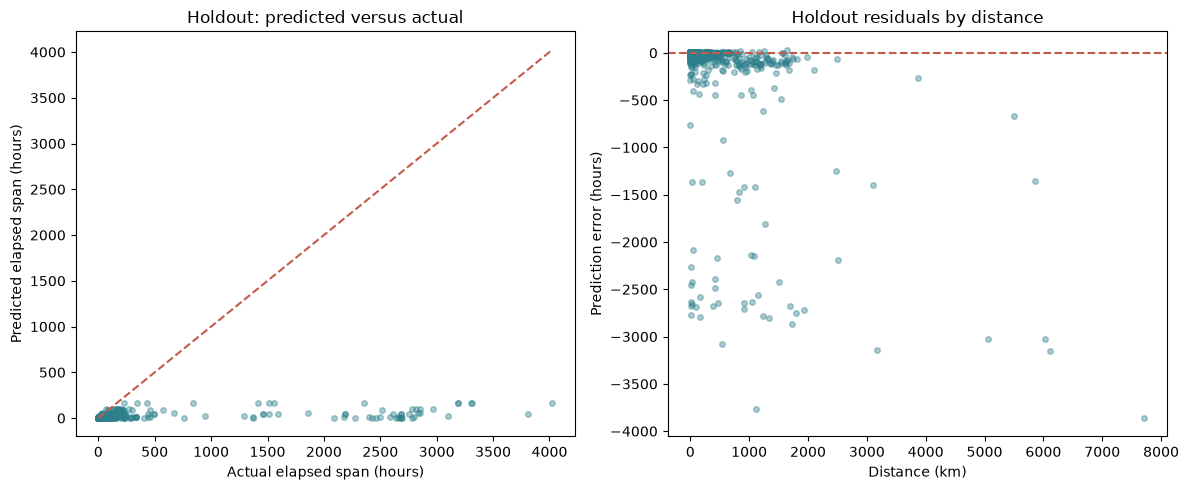

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

actual = holdout_predictions[TARGET].to_numpy()
predicted = holdout_predictions["model_prediction_hours"].to_numpy()
upper = max(float(actual.max()), float(predicted.max()))

axes[0].scatter(actual, predicted, s=16, alpha=0.4, color="#2d7f8b")
axes[0].plot([0, upper], [0, upper], linestyle="--", color="#c45b4a")
axes[0].set(
    title="Holdout: predicted versus actual",
    xlabel="Actual elapsed span (hours)",
    ylabel="Predicted elapsed span (hours)",
)

axes[1].scatter(
    holdout_predictions[FEATURE],
    holdout_predictions["error_hours"],
    s=16,
    alpha=0.4,
    color="#2d7f8b",
)
axes[1].axhline(0, linestyle="--", color="#c45b4a")
axes[1].set(
    title="Holdout residuals by distance",
    xlabel="Distance (km)",
    ylabel="Prediction error (hours)",
)

plt.tight_layout()
plt.show()

### Compare the two tour-duration definitions
Use elapsed_span_hours when the goal is the full elapsed tour window. Use recorded_track_hours when the goal is the sum of recorded track time. The following cell evaluates both targets on the same complete tours and the same chronological split; it never uses one duration field to predict the other.

In [13]:
ALTERNATE_TARGET = "recorded_track_hours"

if ALTERNATE_TARGET not in tours.columns:
    print(f"{ALTERNATE_TARGET} is not available in this tour table.")
else:
    common_tours = tours.dropna(subset=[TARGET, ALTERNATE_TARGET]).copy()
    common_tours = common_tours.loc[
        (common_tours[TARGET] > 0)
        & (common_tours[ALTERNATE_TARGET] > 0)
    ].sort_values("start_time").reset_index(drop=True)

    common_cut = int(TRAIN_FRACTION * len(common_tours))
    common_train_pool = common_tours.iloc[:common_cut].copy()
    common_holdout = common_tours.iloc[common_cut:].copy()
    common_train = common_train_pool.loc[
        ~common_train_pool[QUALITY_FLAG]
    ].copy()

    target_comparison_rows = []
    for target_name in [TARGET, ALTERNATE_TARGET]:
        target_model = build_regressor()
        target_model.fit(common_train[FEATURES], common_train[target_name])
        target_prediction = target_model.predict(common_holdout[FEATURES])
        target_comparison_rows.append({
            "target": target_name,
            "holdout_tours": len(common_holdout),
            **regression_scores(
                common_holdout[target_name],
                target_prediction,
            ),
        })

    display(pd.DataFrame(target_comparison_rows).round(3))

,target,holdout_tours,R2,MAE_hours,RMSE_hours
0,elapsed_span_hours,2679,0.020,56.143,335.829
1,recorded_track_hours,2679,0.712,1.222,4.720


### Interpretation and next modeling decision
Choose the target that matches the intended product:
- elapsed_span_hours estimates the full start-to-finish tour span, including gaps and pauses.
- recorded_track_hours estimates summed recorded track time.
This is a distance-only baseline. The reported holdout and fold scores should guide whether it is ready for the interactive app. If the goal is a pre-departure estimate, confirm that the distance input represents planned distance or is otherwise available before the prediction is made.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

def build_svr_regressor():
    scaled_svr = Pipeline([
        ("scale_distance", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=10.0,
            epsilon=0.1,
            gamma="scale",
            cache_size=300,
        )),
    ])

    return TransformedTargetRegressor(
        regressor=scaled_svr,
        func=np.log1p,
        inverse_func=np.expm1,
    )

svr_model = build_svr_regressor()
print(svr_model)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('scale_distance',
                                                      StandardScaler()),
                                                     ('svr',
                                                      SVR(C=10.0,
                                                          cache_size=300))]))


In [15]:
svr_fold_rows = []
svr_oof_parts = []

for fold, (train_idx, valid_idx) in enumerate(
    TimeSeriesSplit(n_splits=5).split(training_pool),
    start=1,
):
    fold_train = training_pool.iloc[train_idx].copy()
    fold_valid = training_pool.iloc[valid_idx].copy()

    # Exclude quality-review tours from fitting; score every valid fold row.
    fold_train = fold_train.loc[~fold_train[QUALITY_FLAG]]

    fold_model = build_svr_regressor()
    fold_model.fit(fold_train[FEATURES], fold_train[TARGET])
    prediction = fold_model.predict(fold_valid[FEATURES])

    svr_fold_rows.append({
        "fold": fold,
        "train_tours": len(fold_train),
        "validation_tours": len(fold_valid),
        **regression_scores(fold_valid[TARGET], prediction),
    })

    fold_output = fold_valid[[TARGET]].copy()
    fold_output["prediction_hours"] = prediction
    svr_oof_parts.append(fold_output)

svr_fold_results = pd.DataFrame(svr_fold_rows)
svr_oof = pd.concat(svr_oof_parts, ignore_index=True)

display(svr_fold_results.round(3))

print("Mean fold metrics:")
display(
    svr_fold_results[["R2", "MAE_hours", "RMSE_hours"]]
    .mean()
    .round(3)
)

print("Pooled out-of-fold metrics:")
display(
    pd.Series(
        regression_scores(
            svr_oof[TARGET],
            svr_oof["prediction_hours"],
        )
    ).round(3)
)

,fold,train_tours,validation_tours,R2,MAE_hours,RMSE_hours
0,1,1755,1785,-0.004,15.244,70.350
1,2,3510,1785,0.022,17.201,71.279
2,3,5244,1785,0.031,14.088,51.881
3,4,6991,1785,0.044,10.254,35.597
4,5,8750,1785,0.116,9.128,29.028


Mean fold metrics:


R2             0.042
MAE_hours     13.183
RMSE_hours    51.627
dtype: float64

Pooled out-of-fold metrics:


R2             0.027
MAE_hours     13.183
RMSE_hours    54.463
dtype: float64

In [16]:
svr_final_model = build_svr_regressor()
svr_final_model.fit(
    eligible_training[FEATURES],
    eligible_training[TARGET],
)

svr_holdout_prediction = svr_final_model.predict(
    later_holdout[FEATURES]
)

holdout_model_comparison = pd.DataFrame([
    {
        "model": "HistGradientBoosting",
        **regression_scores(
            later_holdout[TARGET],
            holdout_prediction,
        ),
    },
    {
        "model": "RBF SVM",
        **regression_scores(
            later_holdout[TARGET],
            svr_holdout_prediction,
        ),
    },
    {
        "model": "Training mean",
        **regression_scores(
            later_holdout[TARGET],
            baseline_prediction,
        ),
    },
])

display(holdout_model_comparison.round(3))

,model,R2,MAE_hours,RMSE_hours
0,HistGradientBoosting,0.020,56.143,335.829
1,RBF SVM,0.025,55.683,335.038
2,Training mean,-0.018,65.097,342.328


In [17]:
gap_audit = later_holdout[
    ["total_distance_km", TARGET, "recorded_track_hours"]
].copy()

gap_audit["implied_gap_hours"] = (
    gap_audit[TARGET] - gap_audit["recorded_track_hours"]
)
gap_audit["hgb_absolute_error_hours"] = np.abs(
    later_holdout[TARGET].to_numpy() - holdout_prediction
)
gap_audit["svr_absolute_error_hours"] = np.abs(
    later_holdout[TARGET].to_numpy() - svr_holdout_prediction
)

gap_audit["gap_band"] = pd.cut(
    gap_audit["implied_gap_hours"],
    bins=[-np.inf, 0, 1, 6, 24, 168, np.inf],
    labels=["overlap / none", "0–1 h", "1–6 h", "6–24 h", "1–7 days", ">7 days"],
)

gap_summary = (
    gap_audit.dropna(subset=["recorded_track_hours"])
    .groupby("gap_band", observed=True)
    .agg(
        tours=(TARGET, "size"),
        median_gap_hours=("implied_gap_hours", "median"),
        median_hgb_error=("hgb_absolute_error_hours", "median"),
        median_svr_error=("svr_absolute_error_hours", "median"),
        mean_hgb_error=("hgb_absolute_error_hours", "mean"),
        mean_svr_error=("svr_absolute_error_hours", "mean"),
    )
)

display(gap_summary.round(2))

,tours,median_gap_hours,median_hgb_error,median_svr_error,mean_hgb_error,mean_svr_error
gap_band,,,,,,
overlap / none,418,0.00,1.70,1.14,2.11,1.11
0–1 h,712,0.59,3.32,0.82,3.14,1.02
1–6 h,961,2.09,1.78,1.34,1.89,1.72
6–24 h,275,12.46,8.95,11.29,9.62,11.53
1–7 days,221,62.85,56.76,58.72,65.11,67.10
>7 days,92,1348.28,1311.38,1308.83,1396.06,1394.96


In [18]:
fleet_path = PROJECT_ROOT / "data" / "raw" / "fleets" / "fleet.csv"
fleet = pd.read_csv(fleet_path)

fleet_columns = [
    "vehicle_id",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
]

if fleet["vehicle_id"].duplicated().any():
    raise ValueError("Fleet file has duplicate vehicle_id rows.")

tours_enriched = tours.merge(
    fleet[fleet_columns],
    on="vehicle_id",
    how="left",
    validate="many_to_one",
).sort_values("start_time", kind="stable").reset_index(drop=True)

for column in ["gross_vehicle_weight", "total_mass_with_trailer"]:
    tours_enriched[column] = pd.to_numeric(
        tours_enriched[column], errors="coerce"
    )

long_haul_text = (
    tours_enriched["long_haul"]
    .astype("string")
    .str.strip()
    .str.lower()
)
tours_enriched["long_haul"] = (
    long_haul_text
    .map({"true": "Yes", "1": "Yes", "false": "No", "0": "No"})
    .fillna("Unknown")
    .astype("category")
)
tours_enriched["axle_class"] = (
    tours_enriched["axle_class"]
    .astype("string")
    .fillna("Unknown")
    .astype("category")
)

print("Tours:", len(tours_enriched))
print("Tours with fleet specs:", int(tours_enriched["axle_class"].ne("Unknown").sum()))
display(tours_enriched[
    ["total_distance_km", "long_haul", "gross_vehicle_weight",
     "total_mass_with_trailer", "axle_class", TARGET]
].head())

Tours: 13393
Tours with fleet specs: 8895


,total_distance_km,long_haul,gross_vehicle_weight,total_mass_with_trailer,axle_class,elapsed_span_hours
0,1.104,Yes,26000.0,40000.0,41.0,356.641694
1,0.201,No,18000.0,40000.0,98.0,0.180663
2,2.292,No,18000.0,40000.0,98.0,145.539892
3,12.569,No,18000.0,40000.0,98.0,13.756504
4,2.932,No,18000.0,40000.0,98.0,129.997635


#### Define the feature sets and model

In [19]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor

FEATURE_SETS = {
    "distance_only": ["total_distance_km"],
    "distance_plus_route": ["total_distance_km", "long_haul"],
    "distance_plus_fleet_specs": [
        "total_distance_km",
        "gross_vehicle_weight",
        "total_mass_with_trailer",
        "axle_class",
    ],
    "distance_route_and_specs": [
        "total_distance_km",
        "long_haul",
        "gross_vehicle_weight",
        "total_mass_with_trailer",
        "axle_class",
    ],
}

def build_feature_model(feature_columns):
    categorical_columns = [
        column for column in ["long_haul", "axle_class"]
        if column in feature_columns
    ]
    monotonic_constraints = [
        1 if column == "total_distance_km" else 0
        for column in feature_columns
    ]

    regressor = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=2.0,
        categorical_features=categorical_columns or None,
        monotonic_cst=monotonic_constraints,
        early_stopping=False,
        random_state=42,
    )

    return TransformedTargetRegressor(
        regressor=regressor,
        func=np.log1p,
        inverse_func=np.expm1,
    )

#### Compare the feature sets on the same time splits

In [20]:
split_at_enriched = int(0.80 * len(tours_enriched))
training_pool_enriched = tours_enriched.iloc[:split_at_enriched].copy()
holdout_enriched = tours_enriched.iloc[split_at_enriched:].copy()

feature_cv_rows = []

for fold, (train_idx, valid_idx) in enumerate(
    TimeSeriesSplit(n_splits=5).split(training_pool_enriched),
    start=1,
):
    fold_train = training_pool_enriched.iloc[train_idx].copy()
    fold_valid = training_pool_enriched.iloc[valid_idx].copy()
    fold_train = fold_train.loc[~fold_train[QUALITY_FLAG]]

    for model_name, feature_columns in FEATURE_SETS.items():
        model = build_feature_model(feature_columns)
        model.fit(fold_train[feature_columns], fold_train[TARGET])
        prediction = model.predict(fold_valid[feature_columns])

        feature_cv_rows.append({
            "fold": fold,
            "model": model_name,
            **regression_scores(fold_valid[TARGET], prediction),
        })

feature_cv_results = pd.DataFrame(feature_cv_rows)

print("Mean chronological CV metrics:")
display(
    feature_cv_results
    .groupby("model")[["R2", "MAE_hours", "RMSE_hours"]]
    .mean()
    .sort_values("R2", ascending=False)
    .round(3)
)

print("Holdout comparison:")
feature_holdout_rows = []
eligible_training_enriched = training_pool_enriched.loc[
    ~training_pool_enriched[QUALITY_FLAG]
].copy()

for model_name, feature_columns in FEATURE_SETS.items():
    model = build_feature_model(feature_columns)
    model.fit(
        eligible_training_enriched[feature_columns],
        eligible_training_enriched[TARGET],
    )
    prediction = model.predict(holdout_enriched[feature_columns])

    feature_holdout_rows.append({
        "model": model_name,
        **regression_scores(holdout_enriched[TARGET], prediction),
    })

display(
    pd.DataFrame(feature_holdout_rows)
    .sort_values("R2", ascending=False)
    .round(3)
)

Mean chronological CV metrics:


,R2,MAE_hours,RMSE_hours
model,,,
distance_plus_fleet_specs,0.080,13.291,50.741
distance_route_and_specs,0.080,13.271,50.738
distance_plus_route,0.070,13.548,50.953
distance_only,0.069,13.561,50.970


Holdout comparison:


,model,R2,MAE_hours,RMSE_hours
3,distance_route_and_specs,0.030,54.989,334.172
2,distance_plus_fleet_specs,0.029,55.098,334.363
1,distance_plus_route,0.020,56.098,335.813
0,distance_only,0.020,56.143,335.829


In [21]:
long_gap_review = later_holdout.copy()

long_gap_review["implied_gap_hours"] = (
    long_gap_review["elapsed_span_hours"]
    - long_gap_review["recorded_track_hours"]
)
long_gap_review["implied_gap_days"] = (
    long_gap_review["implied_gap_hours"] / 24
)
long_gap_review["hgb_abs_error_hours"] = np.abs(
    later_holdout["elapsed_span_hours"].to_numpy()
    - holdout_prediction
)
long_gap_review["svr_abs_error_hours"] = np.abs(
    later_holdout["elapsed_span_hours"].to_numpy()
    - svr_holdout_prediction
)

extreme_tours = long_gap_review.loc[
    long_gap_review["implied_gap_hours"] > 7 * 24
].sort_values("implied_gap_hours", ascending=False)

print("Holdout tours with implied gaps over 7 days:", len(extreme_tours))

review_columns = [
    "vehicle_id", "tour_id", "start_time", "last_track_start", "end_time",
    "total_distance_km", "track_count", "recorded_track_hours",
    "elapsed_span_hours", "implied_gap_days",
    "requires_quality_review", "duration_incomplete", "duration_unusable",
    "hgb_abs_error_hours", "svr_abs_error_hours",
]
review_columns = [c for c in review_columns if c in extreme_tours.columns]

display(extreme_tours[review_columns].head(30))

Holdout tours with implied gaps over 7 days: 92


,vehicle_id,tour_id,start_time,last_track_start,end_time,total_distance_km,track_count,recorded_track_hours,elapsed_span_hours,implied_gap_days,requires_quality_review,duration_incomplete,duration_unusable,hgb_abs_error_hours,svr_abs_error_hours
12802,162,13436,2023-06-02 14:39:22.866000+00:00,2023-11-17 05:59:55.432000+00:00,2023-11-17 07:35:34.661000+00:00,7714.369,246,174.842559,4024.936610,160.420585,False,False,False,3861.306701,3962.370466
12818,152,13381,2023-06-02 15:56:06.864000+00:00,2023-11-08 07:18:59.840000+00:00,2023-11-08 07:27:34.858000+00:00,1121.179,55,28.396818,3807.524443,157.463651,False,False,False,3761.006174,3765.147713
12804,163,13437,2023-06-02 14:52:16.069000+00:00,2023-10-18 10:59:33.650000+00:00,2023-10-18 11:20:24.953000+00:00,3175.196,98,66.611907,3308.469134,135.077384,False,False,False,3144.839226,3092.773841
12830,81,12876,2023-06-23 14:35:05.523000+00:00,2023-11-08 14:34:21.009000+00:00,2023-11-08 16:06:49.557000+00:00,6118.388,133,113.428634,3313.528898,133.337511,False,False,False,3149.898990,2799.654954
12821,103,12983,2023-06-23 13:05:32.077000+00:00,2023-11-03 11:51:07.197000+00:00,2023-11-03 13:21:39.228000+00:00,5059.362,170,110.050605,3192.268653,128.425752,False,False,False,3028.638745,3129.601049
12819,98,12934,2023-06-23 12:39:02.031000+00:00,2023-10-30 14:49:26.839000+00:00,2023-10-30 15:08:15.336000+00:00,531.278,52,18.256397,3098.487029,128.342943,True,True,False,3080.654841,3085.662993
12832,69,12855,2023-06-23 15:25:21.211000+00:00,2023-11-03 12:50:24.756000+00:00,2023-11-03 15:30:21.643000+00:00,6029.902,257,139.250111,3192.083453,127.201389,True,True,False,3028.453545,2826.377636
12817,102,12981,2023-06-02 15:54:08.334000+00:00,2023-10-04 07:37:15.941000+00:00,2023-10-04 07:53:37.206000+00:00,1728.772,93,34.474767,2967.991353,122.229858,False,False,False,2870.544374,2873.312150
12808,137,13184,2023-06-02 15:04:23.817000+00:00,2023-09-29 09:08:13.055000+00:00,2023-09-29 09:35:05.160000+00:00,1795.259,28,29.244122,2850.511484,117.552807,False,False,False,2753.064505,2755.564944
12811,133,13177,2023-06-02 15:20:55.039000+00:00,2023-09-29 13:04:58.796000+00:00,2023-09-29 13:22:50.041000+00:00,1337.172,132,37.175738,2854.031945,117.369009,False,False,False,2799.237874,2794.226239


In [22]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

tracks_path = root / "data/processed/engineered_tracks.csv"
print("Reading:", tracks_path)

tracks = pd.read_csv(tracks_path)

required = [
    "vehicle_id", "tour_id", "track_id",
    "start_time", "stop_time", "distance_km",
]
missing = [column for column in required if column not in tracks.columns]
if missing:
    raise ValueError(f"Missing columns in engineered_tracks.csv: {missing}")

tracks["start_time"] = pd.to_datetime(
    tracks["start_time"], utc=True, errors="coerce"
)
tracks["stop_time"] = pd.to_datetime(
    tracks["stop_time"], utc=True, errors="coerce"
)
tracks["distance_km"] = pd.to_numeric(
    tracks["distance_km"], errors="coerce"
)

print("Track rows:", len(tracks))
tracks.head()

Reading: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-/data/processed/engineered_tracks.csv
Track rows: 151598


,track_id,vehicle_id,tour_id,start_time,stop_time,distance,track_gap,avg_speed,max_speed,n_signal_loss,d_signal_loss,r_signal_loss,avg_hdop,home_base,long_haul,rest_area,service_area_fuel,industrial_area,cid,fleet_test_id,gross_vehicle_weight,total_mass_with_trailer,axle_class,raw_observations,telemetry_span_seconds,raw_speed_mean,raw_speed_std,raw_speed_min,raw_speed_max,raw_hdop_mean,raw_hdop_median,raw_hdop_max,missing_speed_count,missing_hdop_count,insufficient_telemetry,start_time_parsed,stop_time_parsed,duration_seconds,duration_invalid,avg_speed_negative,avg_speed_gt_max_speed,raw_speed_missing,n_signal_loss_negative,r_signal_loss_missing,r_signal_loss_out_of_range,distance_missing,zero_distance,zero_distance_speed_issue,track_gap_missing,limited_telemetry,insufficient_core_telemetry,avg_speed_valid,max_speed_valid,n_signal_loss_valid,r_signal_loss_valid,distance_km,avg_speed_kmh,max_speed_kmh,raw_speed_mean_kmh,duration_minutes,avg_speed_implausible,speed_distance_validity,signal_loss_validity
0,0,1,0,2021-09-10 09:04:53.598000+00:00,2021-09-10 10:07:57.395000+00:00,30751.0,NaN,8.13,20.58,0.0,0.0,0.0,0.612354,False,False,False,False,True,149,1,18000.0,40000.0,98.0,37126,3783.793,8.009470,7.420131,0.0,20.58,0.612463,0.6,2.1,0,0,False,2021-09-10 09:04:53.598000+00:00,2021-09-10 10:07:57.395000+00:00,3783.797,False,False,False,False,False,False,False,False,False,False,True,False,False,8.13,20.58,0.0,0.0,30.751,29.268,74.088,28.834092,63.063283,False,valid,valid
1,1,1,0,2021-09-10 10:57:54.718000+00:00,2021-09-10 11:13:53.221000+00:00,7762.0,37.504057,8.10,21.79,0.0,0.0,0.0,1.230128,False,False,False,False,True,-1,1,18000.0,40000.0,98.0,9406,958.498,7.892118,6.804812,0.0,21.79,1.226558,0.9,5.4,0,0,False,2021-09-10 10:57:54.718000+00:00,2021-09-10 11:13:53.221000+00:00,958.503,False,False,False,False,False,False,False,False,False,False,False,False,False,8.10,21.79,0.0,0.0,7.762,29.160,78.444,28.411624,15.975050,False,valid,valid
2,2,1,0,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,19432.0,4.895394,7.28,24.75,0.0,0.0,0.0,0.549358,True,False,False,False,True,0,1,18000.0,40000.0,98.0,26206,2670.652,7.141439,8.224648,0.0,24.75,0.547550,0.5,2.2,0,0,False,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,2670.656,False,False,False,False,False,False,False,False,False,False,False,False,False,7.28,24.75,0.0,0.0,19.432,26.208,89.100,25.709182,44.510933,False,valid,valid
3,3,1,1,2021-09-10 12:21:35.547000+00:00,2021-09-10 12:25:26.391000+00:00,56.0,3.836167,0.24,2.44,0.0,0.0,0.0,0.852446,True,False,False,False,True,0,1,18000.0,40000.0,98.0,2266,230.840,0.126748,0.330134,0.0,2.44,0.848897,0.8,1.0,0,0,False,2021-09-10 12:21:35.547000+00:00,2021-09-10 12:25:26.391000+00:00,230.844,False,False,False,False,False,False,False,False,False,False,False,False,False,0.24,2.44,0.0,0.0,0.056,0.864,8.784,0.456291,3.847400,False,valid,valid
4,4,1,1,2021-09-10 13:39:48.925000+00:00,2021-09-10 13:45:05.392000+00:00,201.0,12.816326,0.64,3.80,0.0,0.0,0.0,0.656429,True,False,False,False,True,0,1,18000.0,40000.0,98.0,3106,316.463,0.484833,0.834812,0.0,3.80,0.654894,0.7,1.2,0,0,False,2021-09-10 13:39:48.925000+00:00,2021-09-10 13:45:05.392000+00:00,316.467,False,False,False,False,False,False,False,False,False,False,False,False,False,0.64,3.80,0.0,0.0,0.201,2.304,13.680,1.745397,5.274450,False,valid,valid


In [23]:
keys = ["vehicle_id", "tour_id"]

tracks["track_duration_hours"] = (
    tracks["stop_time"] - tracks["start_time"]
).dt.total_seconds() / 3600

tracks["track_speed_kmh"] = (
    tracks["distance_km"]
    / tracks["track_duration_hours"].where(
        tracks["track_duration_hours"] > 0
    )
)

tracks["flag_missing_id_or_time"] = (
    tracks[keys].isna().any(axis=1)
    | tracks["start_time"].isna()
    | tracks["stop_time"].isna()
)
tracks["flag_invalid_duration"] = (
    tracks["track_duration_hours"].isna()
    | tracks["track_duration_hours"].le(0)
)
tracks["flag_track_over_24h"] = tracks["track_duration_hours"].gt(24)
tracks["flag_missing_distance"] = tracks["distance_km"].isna()
tracks["flag_negative_distance"] = tracks["distance_km"].lt(0)
tracks["flag_speed_over_120"] = tracks["track_speed_kmh"].gt(120)

flag_columns = [
    "flag_missing_id_or_time",
    "flag_invalid_duration",
    "flag_track_over_24h",
    "flag_missing_distance",
    "flag_negative_distance",
    "flag_speed_over_120",
]
tracks["track_telemetry_flagged"] = tracks[flag_columns].any(axis=1)

# Tracks without usable vehicle, tour, or timestamps cannot be grouped.
assignable = tracks.loc[~tracks["flag_missing_id_or_time"]].copy()
assignable = assignable.sort_values(keys + ["start_time"])

assignable["gap_from_previous_h"] = (
    assignable["start_time"]
    - assignable.groupby(keys)["stop_time"].shift()
).dt.total_seconds() / 3600

GAP_HOURS = 24

assignable["new_episode"] = (
    assignable["gap_from_previous_h"] > GAP_HOURS
)
assignable["episode_no"] = (
    assignable.groupby(keys)["new_episode"].cumsum().astype(int)
)

assignable["internal_gap_h"] = assignable["gap_from_previous_h"].where(
    ~assignable["new_episode"]
)
assignable["boundary_gap_before_h"] = assignable["gap_from_previous_h"].where(
    assignable["new_episode"]
)
assignable["valid_track_hours"] = assignable["track_duration_hours"].where(
    assignable["track_duration_hours"] > 0
)

print("Assignable track rows:", len(assignable))
print("Flagged track rows:", int(assignable["track_telemetry_flagged"].sum()))

Assignable track rows: 151256
Flagged track rows: 293


In [24]:
episodes = (
    assignable.groupby(keys + ["episode_no"], as_index=False)
    .agg(
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
        total_distance_km=(
            "distance_km",
            lambda values: values.sum(min_count=1),
        ),
        recorded_track_hours=(
            "valid_track_hours",
            lambda values: values.sum(min_count=1),
        ),
        track_count=("track_id", "size"),
        max_internal_gap_h=("internal_gap_h", "max"),
        boundary_gap_before_h=("boundary_gap_before_h", "first"),
        flagged_track_count=("track_telemetry_flagged", "sum"),
    )
)

episodes["elapsed_span_hours"] = (
    episodes["end_time"] - episodes["start_time"]
).dt.total_seconds() / 3600
episodes["telemetry_flagged"] = episodes["flagged_track_count"] > 0

print("Trip episodes:", len(episodes))
print("Flagged episodes:", int(episodes["telemetry_flagged"].sum()))

display(
    episodes.nlargest(10, "elapsed_span_hours")[
        [
            "vehicle_id", "tour_id", "episode_no",
            "start_time", "end_time", "track_count",
            "total_distance_km", "elapsed_span_hours",
            "max_internal_gap_h", "telemetry_flagged",
        ]
    ]
)

Trip episodes: 15289
Flagged episodes: 276


,vehicle_id,tour_id,episode_no,start_time,end_time,track_count,total_distance_km,elapsed_span_hours,max_internal_gap_h,telemetry_flagged
7281,39,6916,0,2022-01-07 16:48:21.234000+00:00,2022-02-10 04:48:27.018000+00:00,903,38.330,804.001607,14.170656,False
10572,56,10060,0,2022-03-21 19:37:17.734000+00:00,2022-04-20 08:09:56.849000+00:00,571,1822.840,708.544199,15.550604,True
2968,17,2862,0,2021-12-20 13:55:17.077000+00:00,2022-01-18 08:22:12.399000+00:00,2134,159.407,690.448701,6.472883,False
6958,35,6641,0,2021-12-20 17:57:49.230000+00:00,2022-01-14 18:17:19.410000+00:00,659,190.393,600.325050,22.143894,False
6352,31,6078,0,2021-12-23 11:43:40.051000+00:00,2022-01-14 06:53:07.748000+00:00,655,49.296,523.157694,14.195129,False
7155,38,6795,0,2021-11-17 01:13:42.439000+00:00,2021-12-08 09:14:36.865000+00:00,197,3350.770,512.015118,13.459506,False
1345,7,1299,1,2021-12-31 21:01:36.034000+00:00,2022-01-20 05:25:23.508000+00:00,509,37.782,464.396521,23.953838,False
6955,35,6639,1,2021-11-29 19:28:34.298000+00:00,2021-12-18 17:09:57.262000+00:00,244,167.988,453.689712,22.371422,False
10627,57,10114,0,2022-01-07 17:42:50.404000+00:00,2022-01-26 09:07:18.004000+00:00,809,319.580,447.407667,4.160109,False
2166,13,2104,0,2021-12-23 22:16:45.836000+00:00,2022-01-11 11:34:24.052000+00:00,403,23.720,445.293949,10.858606,False


In [25]:
df = episodes.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=[
        "start_time", "vehicle_id",
        "total_distance_km", "elapsed_span_hours",
    ]
)
df = df.loc[
    (df["total_distance_km"] >= 0)
    & (df["elapsed_span_hours"] > 0)
].sort_values("start_time").reset_index(drop=True)

# Keep the latest 20% of episodes as a chronological holdout.
cut = int(0.80 * len(df))
train = df.iloc[:cut].copy()
test = df.iloc[cut:].copy()

# Exclude flagged episodes from training; keep them in the main holdout score.
train = train.loc[~train["telemetry_flagged"]].copy()
scorable_test = test.dropna(
    subset=["vehicle_id", "total_distance_km", "elapsed_span_hours"]
).copy()

features = ["vehicle_id", "total_distance_km"]
target = "elapsed_span_hours"

preprocessor = ColumnTransformer([
    (
        "vehicle",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ["vehicle_id"],
    ),
    ("distance", StandardScaler(), ["total_distance_km"]),
])

model = make_pipeline(
    preprocessor,
    HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=5,
        random_state=42,
    ),
)

model.fit(train[features], train[target])
predictions = model.predict(scorable_test[features])

baseline = DummyRegressor(strategy="mean")
baseline.fit(train[features], train[target])
baseline_predictions = baseline.predict(scorable_test[features])

def show_scores(label, actual, predicted):
    print(
        f"{label}: n={len(actual)}, "
        f"R²={r2_score(actual, predicted):.3f}, "
        f"MAE={mean_absolute_error(actual, predicted):.2f} hours, "
        f"RMSE={mean_squared_error(actual, predicted) ** 0.5:.2f} hours"
    )

print("Training episodes:", len(train))
print("Held-out episodes:", len(scorable_test))
show_scores("Mean baseline", scorable_test[target], baseline_predictions)
show_scores("24-hour episode model", scorable_test[target], predictions)

Training episodes: 12067
Held-out episodes: 3058
Mean baseline: n=3058, R²=-0.053, MAE=20.36 hours, RMSE=33.48 hours
24-hour episode model: n=3058, R²=0.462, MAE=13.34 hours, RMSE=23.93 hours


In [26]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

data_path = root / "data/processed/tour_level/retained_tours_quality_checked.csv"
df = pd.read_csv(data_path)

df["start_time"] = pd.to_datetime(
    df["start_time"], utc=True, errors="coerce"
)

for column in ["total_distance_km", "elapsed_span_hours"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Rows:", len(df))
print("Unique vehicle-tour pairs:",
      df[["vehicle_id", "tour_id"]].drop_duplicates().shape[0])
print("Duplicate vehicle-tour rows:",
      int(df.duplicated(["vehicle_id", "tour_id"]).sum()))
print("Columns:", df.columns.tolist())

df.head()

Rows: 13413
Unique vehicle-tour pairs: 13413
Duplicate vehicle-tour rows: 0
Columns: ['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review']


,vehicle_id,tour_id,track_count,start_time,last_track_start,end_time,total_distance_km,total_valid_track_duration_seconds,valid_duration_track_count,home_base_endpoint,elapsed_span_hours,recorded_track_hours,distance_based_avg_speed_kmh,fleet_test_id,long_haul,rest_area,service_area_fuel,industrial_area,home_base,cid,negative_elapsed_span,non_positive_distance,duration_incomplete,duration_unusable,high_distance_based_speed,requires_quality_review
0,1,0,3,2021-09-10 09:04:53.598000+00:00,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,57.945,7412.956,3,True,3.082557,2.059154,28.140191,1,False,False,False,True,False,149,False,False,False,False,False,False
1,1,1,7,2021-09-10 12:21:35.547000+00:00,2021-09-13 06:08:10.018000+00:00,2021-09-13 06:08:26.837000+00:00,0.371,763.286,7,True,65.780914,0.212024,1.749803,1,False,False,False,True,True,0,False,False,False,False,False,False
2,1,2,8,2021-09-13 06:25:03.766000+00:00,2021-09-14 11:24:50.310000+00:00,2021-09-14 11:45:39.906000+00:00,36.554,4767.617,8,True,29.343372,1.324338,27.601714,1,False,False,False,True,False,301,False,False,False,False,False,False
3,1,3,104,2021-09-14 11:49:23.603000+00:00,2021-10-07 08:44:23.587000+00:00,2021-10-07 08:49:40.058000+00:00,6.757,17947.817,104,True,549.004571,4.985505,1.355329,1,False,False,False,True,True,0,False,False,False,False,False,False
4,1,4,16,2021-10-07 10:19:52.098000+00:00,2021-10-09 06:35:21.071000+00:00,2021-10-09 07:59:24.414000+00:00,1291.041,74143.179,16,True,45.658977,20.595327,62.686112,1,False,False,False,True,False,149,False,False,False,False,False,False


In [27]:
# Calendar features derived from the tour start time.
df["start_month"] = df["start_time"].dt.month
df["start_weekday"] = df["start_time"].dt.weekday
df["start_hour"] = df["start_time"].dt.hour

numeric_candidates = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_month",
    "start_weekday",
    "start_hour",
]

categorical_candidates = [
    "vehicle_id",
    "long_haul",
    "route_type",
]

numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]

# Handle numeric columns and categorical missing values.
for column in numeric_features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

for column in categorical_features:
    df[column] = df[column].fillna("Unknown").astype(str)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["start_time", "total_distance_km", "elapsed_span_hours"]
)
df = df.loc[df["elapsed_span_hours"] > 0]
df = df.sort_values("start_time").reset_index(drop=True)

feature_sets = {
    "distance_only": ["total_distance_km"],
    "available_tour_inputs": [
        c for c in numeric_features + categorical_features
        if c in df.columns
    ],
}

print("Numeric inputs available:", numeric_features)
print("Categorical inputs available:", categorical_features)
print("Tours used:", len(df))

Numeric inputs available: ['total_distance_km', 'start_month', 'start_weekday', 'start_hour']
Categorical inputs available: ['vehicle_id', 'long_haul']
Tours used: 13408


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cut = int(0.80 * len(df))
train = df.iloc[:cut].copy()
holdout = df.iloc[cut:].copy()

target = "elapsed_span_hours"

def make_preprocessor(features):
    numeric = [c for c in features if c in numeric_features]
    categorical = [c for c in features if c in categorical_features]

    transformers = []

    if numeric:
        transformers.append((
            "numeric",
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
            ),
            numeric,
        ))

    if categorical:
        transformers.append((
            "categorical",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
            categorical,
        ))

    return ColumnTransformer(transformers)

results = []

# Mean baseline, scored on the same held-out tours.
baseline_prediction = np.full(
    len(holdout), train[target].mean()
)
results.append({
    "model": "training_mean_baseline",
    "features": "none",
    "R2": r2_score(holdout[target], baseline_prediction),
    "MAE_hours": mean_absolute_error(holdout[target], baseline_prediction),
    "RMSE_hours": mean_squared_error(
        holdout[target], baseline_prediction
    ) ** 0.5,
})

for feature_name, features in feature_sets.items():
    for target_mode in ["raw", "log1p"]:
        model = make_pipeline(
            make_preprocessor(features),
            HistGradientBoostingRegressor(
                max_iter=150,
                learning_rate=0.05,
                max_leaf_nodes=15,
                min_samples_leaf=30,
                l2_regularization=5,
                random_state=42,
            ),
        )

        y_train = train[target]
        if target_mode == "log1p":
            y_train = np.log1p(y_train)

        model.fit(train[features], y_train)
        prediction = model.predict(holdout[features])

        # Convert log predictions back to hours before scoring.
        if target_mode == "log1p":
            prediction = np.expm1(prediction)

        results.append({
            "model": f"HistGradientBoosting_{target_mode}",
            "features": feature_name,
            "R2": r2_score(holdout[target], prediction),
            "MAE_hours": mean_absolute_error(holdout[target], prediction),
            "RMSE_hours": mean_squared_error(
                holdout[target], prediction
            ) ** 0.5,
        })

results_df = pd.DataFrame(results).sort_values(
    ["R2", "MAE_hours"], ascending=[False, True]
)
display(results_df.round(3))

,model,features,R2,MAE_hours,RMSE_hours
3,HistGradientBoosting_raw,available_tour_inputs,0.039,57.353,332.498
1,HistGradientBoosting_raw,distance_only,0.028,61.177,334.288
4,HistGradientBoosting_log1p,available_tour_inputs,0.022,55.525,335.276
2,HistGradientBoosting_log1p,distance_only,0.013,56.545,336.960
0,training_mean_baseline,none,-0.017,65.949,341.965


In [29]:
# Refit the best model from the previous comparison.
features = feature_sets["available_tour_inputs"]

best_model = make_pipeline(
    make_preprocessor(features),
    HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=5,
        random_state=42,
    ),
)

best_model.fit(train[features], train[target])

audit = holdout.copy()
audit["prediction_hours"] = best_model.predict(audit[features])
audit["absolute_error_hours"] = (
    audit[target] - audit["prediction_hours"]
).abs()

# See how errors vary across short to long tours.
audit["duration_band"] = pd.qcut(
    audit[target], q=5, duplicates="drop"
)

display(
    audit.groupby("duration_band", observed=True)
    .agg(
        tours=(target, "size"),
        min_actual_hours=(target, "min"),
        median_actual_hours=(target, "median"),
        median_prediction_hours=("prediction_hours", "median"),
        median_absolute_error=("absolute_error_hours", "median"),
        mean_absolute_error=("absolute_error_hours", "mean"),
    )
    .round(2)
)

# These fields help diagnose errors; they are not model inputs.
diagnostic_columns = [
    "vehicle_id",
    "tour_id",
    "start_time",
    "total_distance_km",
    "elapsed_span_hours",
    "prediction_hours",
    "absolute_error_hours",
    "recorded_track_hours",
    "implied_gap_days",
    "requires_quality_review",
    "duration_incomplete",
    "duration_unusable",
]
diagnostic_columns = [
    column for column in diagnostic_columns if column in audit.columns
]

display(
    audit.sort_values("absolute_error_hours", ascending=False)[
        diagnostic_columns
    ].head(20)
)

,tours,min_actual_hours,median_actual_hours,median_prediction_hours,median_absolute_error,mean_absolute_error
duration_band,,,,,,
"(0.00014999999999999996, 0.698]",537,0.00,0.11,3.51,3.39,5.74
"(0.698, 2.825]",536,0.71,1.59,5.25,3.69,7.47
"(2.825, 5.386]",536,2.83,4.18,7.12,3.42,5.43
"(5.386, 11.86]",536,5.39,7.90,8.36,3.14,5.36
"(11.86, 4024.937]",537,11.86,43.69,18.75,24.12,262.48


,vehicle_id,tour_id,start_time,total_distance_km,elapsed_span_hours,prediction_hours,absolute_error_hours,recorded_track_hours,requires_quality_review,duration_incomplete,duration_unusable
12815,162,13436,2023-06-02 14:39:22.866000+00:00,7714.369,4024.936610,179.599012,3845.337598,174.842559,False,False,False
12831,152,13381,2023-06-02 15:56:06.864000+00:00,1121.179,3807.524443,59.591023,3747.933419,28.396818,False,False,False
12843,81,12876,2023-06-23 14:35:05.523000+00:00,6118.388,3313.528898,179.599012,3133.929887,113.428634,False,False,False
12817,163,13437,2023-06-02 14:52:16.069000+00:00,3175.196,3308.469134,179.599012,3128.870123,66.611907,False,False,False
12832,98,12934,2023-06-23 12:39:02.031000+00:00,531.278,3098.487029,35.645073,3062.841957,18.256397,True,True,False
12834,103,12983,2023-06-23 13:05:32.077000+00:00,5059.362,3192.268653,179.599012,3012.669641,110.050605,False,False,False
12845,69,12855,2023-06-23 15:25:21.211000+00:00,6029.902,3192.083453,179.599012,3012.484442,139.250111,True,True,False
12830,102,12981,2023-06-02 15:54:08.334000+00:00,1728.772,2967.991353,116.592749,2851.398604,34.474767,False,False,False
12824,133,13177,2023-06-02 15:20:55.039000+00:00,1337.172,2854.031945,76.499563,2777.532382,37.175738,False,False,False
12825,141,13219,2023-06-02 15:24:30.866000+00:00,1228.580,2836.415155,76.499563,2759.915592,28.477752,False,False,False


In [30]:
audit["implied_gap_days"] = (
    audit["elapsed_span_hours"] - audit["recorded_track_hours"]
) / 24

audit["squared_error"] = audit["absolute_error_hours"] ** 2

audit["gap_band"] = pd.cut(
    audit["implied_gap_days"],
    bins=[-np.inf, 0, 1, 7, 30, np.inf],
    labels=["overlap / none", "0–1 day", "1–7 days", "7–30 days", ">30 days"],
)

gap_error_summary = (
    audit.groupby("gap_band", observed=True)
    .agg(
        tours=("elapsed_span_hours", "size"),
        median_gap_days=("implied_gap_days", "median"),
        median_elapsed_hours=("elapsed_span_hours", "median"),
        mean_absolute_error=("absolute_error_hours", "mean"),
        squared_error_sum=("squared_error", "sum"),
    )
)

gap_error_summary["share_of_squared_error_pct"] = (
    100
    * gap_error_summary["squared_error_sum"]
    / gap_error_summary["squared_error_sum"].sum()
)

display(gap_error_summary.round(2))

,tours,median_gap_days,median_elapsed_hours,mean_absolute_error,squared_error_sum,share_of_squared_error_pct
gap_band,,,,,,
overlap / none,421,0.00,0.10,5.98,4.023997e+04,0.01
0–1 day,1948,0.06,4.48,6.46,2.009273e+05,0.07
1–7 days,221,2.62,70.26,53.10,9.079507e+05,0.31
7–30 days,41,10.00,274.83,257.09,3.252367e+06,1.10
>30 days,51,107.68,2589.89,2283.13,2.921061e+08,98.52


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

groups = {
    "All held-out tours": audit,
    "Implied gap ≤ 7 days": audit[audit["implied_gap_days"] <= 7],
    "Implied gap > 7 days": audit[audit["implied_gap_days"] > 7],
}

rows = []

for label, subset in groups.items():
    actual = subset["elapsed_span_hours"]
    predicted = subset["prediction_hours"]

    rows.append({
        "group": label,
        "tours": len(subset),
        "R2": r2_score(actual, predicted),
        "MAE_hours": mean_absolute_error(actual, predicted),
        "RMSE_hours": mean_squared_error(actual, predicted) ** 0.5,
    })

display(pd.DataFrame(rows).round(3))

,group,tours,R2,MAE_hours,RMSE_hours
0,All held-out tours,2682,0.039,57.353,332.498
1,Implied gap ≤ 7 days,2590,0.403,10.363,21.064
2,Implied gap > 7 days,92,-1.392,1380.223,1791.764


In [32]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

data_path = root / "data/processed/tour_level/retained_tours_quality_checked.csv"
tour_df = pd.read_csv(data_path)

target = "elapsed_span_hours"

tour_df["start_time"] = pd.to_datetime(
    tour_df["start_time"], utc=True, errors="coerce"
)

if "end_time" in tour_df.columns:
    tour_df["end_time"] = pd.to_datetime(
        tour_df["end_time"], utc=True, errors="coerce"
    )
else:
    tour_df["end_time"] = pd.NaT

for column in [
    target,
    "total_distance_km",
    "recorded_track_hours",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
]:
    if column in tour_df.columns:
        tour_df[column] = pd.to_numeric(tour_df[column], errors="coerce")

# Fallback end time is used only to decide when a past tour was completed.
# The current tour's target is never added to its own input features.
missing_end = tour_df["end_time"].isna() & tour_df["start_time"].notna()
tour_df.loc[missing_end, "end_time"] = (
    tour_df.loc[missing_end, "start_time"]
    + pd.to_timedelta(
        tour_df.loc[missing_end, target], unit="h"
    )
)

if "recorded_track_hours" in tour_df.columns:
    tour_df["gap_days_for_history"] = (
        tour_df[target] - tour_df["recorded_track_hours"]
    ) / 24
else:
    tour_df["gap_days_for_history"] = np.nan

tour_df["start_month"] = tour_df["start_time"].dt.month
tour_df["start_weekday"] = tour_df["start_time"].dt.weekday
tour_df["start_hour"] = tour_df["start_time"].dt.hour

history_features = [
    "completed_tour_history_count",
    "prior_median_elapsed_hours",
    "prior_median_gap_days",
    "prior_long_gap_rate",
    "previous_completed_elapsed_hours",
    "previous_completed_distance_km",
]

for column in history_features:
    tour_df[column] = np.nan

# For each tour, use only tours from that vehicle that had ended by its start.
for vehicle_id, group in tour_df.dropna(subset=["vehicle_id"]).groupby(
    "vehicle_id", sort=False
):
    group = group.sort_values("start_time")
    past_tours = []

    for row_index, row in group.iterrows():
        completed = [
            past for past in past_tours
            if past["end_time"] <= row["start_time"]
        ]

        if completed:
            prior_elapsed = np.array(
                [past["elapsed"] for past in completed
                 if pd.notna(past["elapsed"])],
                dtype=float,
            )
            prior_gaps = np.array(
                [past["gap_days"] for past in completed
                 if pd.notna(past["gap_days"])],
                dtype=float,
            )

            tour_df.at[row_index, "completed_tour_history_count"] = len(completed)

            if len(prior_elapsed):
                tour_df.at[row_index, "prior_median_elapsed_hours"] = (
                    np.median(prior_elapsed)
                )

            if len(prior_gaps):
                tour_df.at[row_index, "prior_median_gap_days"] = (
                    np.median(prior_gaps)
                )
                tour_df.at[row_index, "prior_long_gap_rate"] = (
                    np.mean(prior_gaps > 7)
                )

            previous = max(completed, key=lambda past: past["end_time"])
            tour_df.at[row_index, "previous_completed_elapsed_hours"] = (
                previous["elapsed"]
            )
            tour_df.at[row_index, "previous_completed_distance_km"] = (
                previous["distance"]
            )

        # Add this tour to history only after preparing its own features.
        if pd.notna(row["end_time"]):
            past_tours.append({
                "end_time": row["end_time"],
                "elapsed": row[target],
                "distance": row.get("total_distance_km", np.nan),
                "gap_days": row.get("gap_days_for_history", np.nan),
            })

plan_candidates = [
    "planned_stop_count",
    "planned_dwell_hours",
    "route_type",
]
print("Tours:", len(tour_df))
print("Duplicate vehicle-tour pairs:",
      int(tour_df.duplicated(["vehicle_id", "tour_id"]).sum()))
print("Planned/route fields present:",
      [c for c in plan_candidates if c in tour_df.columns])
print("Tours with prior completed history:",
      int(tour_df["completed_tour_history_count"].notna().sum()))

display(
    tour_df[
        [
            "vehicle_id", "tour_id", "start_time", target,
            "completed_tour_history_count",
            "prior_median_elapsed_hours",
            "prior_median_gap_days",
            "prior_long_gap_rate",
        ]
    ].head(10)
)

Tours: 13413
Duplicate vehicle-tour pairs: 0
Planned/route fields present: []
Tours with prior completed history: 13298


,vehicle_id,tour_id,start_time,elapsed_span_hours,completed_tour_history_count,prior_median_elapsed_hours,prior_median_gap_days,prior_long_gap_rate
0,1,0,2021-09-10 09:04:53.598000+00:00,3.082557,NaN,NaN,NaN,NaN
1,1,1,2021-09-10 12:21:35.547000+00:00,65.780914,1.0,3.082557,0.042642,0.000000
2,1,2,2021-09-13 06:25:03.766000+00:00,29.343372,2.0,34.431735,1.387339,0.000000
3,1,3,2021-09-14 11:49:23.603000+00:00,549.004571,3.0,29.343372,1.167460,0.000000
4,1,4,2021-10-07 10:19:52.098000+00:00,45.658977,4.0,47.562143,1.949748,0.250000
5,1,5,2021-10-09 08:07:14.706000+00:00,45.919269,5.0,45.658977,1.167460,0.200000
6,1,6,2021-10-11 06:12:38.147000+00:00,5.244135,6.0,45.789123,1.382630,0.166667
7,1,7,2021-10-11 11:39:45.708000+00:00,0.054606,7.0,45.658977,1.167460,0.142857
8,1,8,2021-10-11 13:05:55.392000+00:00,48.665134,8.0,37.501174,1.105889,0.125000
9,1,9,2021-10-13 15:14:26.905000+00:00,0.370888,9.0,45.658977,1.167460,0.111111


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

model_df = tour_df.copy()

numeric_candidates = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_month",
    "start_weekday",
    "start_hour",
]

categorical_candidates = [
    "vehicle_id",
    "long_haul",
    "route_type",
]

history_candidates = [
    "completed_tour_history_count",
    "prior_median_elapsed_hours",
    "prior_median_gap_days",
    "prior_long_gap_rate",
    "previous_completed_elapsed_hours",
    "previous_completed_distance_km",
]

numeric_features = [c for c in numeric_candidates if c in model_df.columns]
categorical_features = [
    c for c in categorical_candidates if c in model_df.columns
]
history_features = [
    c for c in history_candidates
    if c in model_df.columns and model_df[c].notna().any()
]

for column in numeric_features + history_features:
    model_df[column] = pd.to_numeric(model_df[column], errors="coerce")

for column in categorical_features:
    model_df[column] = model_df[column].fillna("Unknown").astype(str)

model_df[target] = pd.to_numeric(model_df[target], errors="coerce")
model_df = model_df.dropna(
    subset=["start_time", "total_distance_km", target]
)
model_df = model_df.sort_values("start_time").reset_index(drop=True)

base_features = list(dict.fromkeys(numeric_features + categorical_features))
history_model_features = list(dict.fromkeys(base_features + history_features))

print("Base tour features:", base_features)
print("Past-tour history features:", history_features)
print("Rows used:", len(model_df))

# Keep the latest 20% as the same chronological holdout.
cut = int(0.80 * len(model_df))
train = model_df.iloc[:cut].copy()
holdout = model_df.iloc[cut:].copy()

def make_tour_model(features):
    numeric = [
        c for c in features
        if c in numeric_features or c in history_features
    ]
    categorical = [c for c in features if c in categorical_features]

    transforms = []

    if numeric:
        transforms.append((
            "numeric",
            SimpleImputer(strategy="median"),
            numeric,
        ))

    if categorical:
        transforms.append((
            "categorical",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
            categorical,
        ))

    preprocessor = ColumnTransformer(transforms)

    return make_pipeline(
        preprocessor,
        HistGradientBoostingRegressor(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=30,
            l2_regularization=5,
            random_state=42,
        ),
    )

results = []

for model_name, features in [
    ("base_tour_inputs", base_features),
    ("base_plus_completed_tour_history", history_model_features),
]:
    model = make_tour_model(features)
    model.fit(train[features], train[target])
    holdout_predictions = model.predict(holdout[features])

    groups = {
        "all_tours": np.ones(len(holdout), dtype=bool),
        "gap_le_7_days": holdout["gap_days_for_history"].le(7).to_numpy(),
        "gap_gt_7_days": holdout["gap_days_for_history"].gt(7).to_numpy(),
    }

    for group_name, mask in groups.items():
        actual = holdout.loc[mask, target]
        predicted = holdout_predictions[mask]

        results.append({
            "model": model_name,
            "group": group_name,
            "tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": mean_squared_error(actual, predicted) ** 0.5,
        })

display(pd.DataFrame(results).round(3))

Base tour features: ['total_distance_km', 'start_month', 'start_weekday', 'start_hour', 'vehicle_id', 'long_haul']
Past-tour history features: ['completed_tour_history_count', 'prior_median_elapsed_hours', 'prior_median_gap_days', 'prior_long_gap_rate', 'previous_completed_elapsed_hours', 'previous_completed_distance_km']
Rows used: 13408


,model,group,tours,R2,MAE_hours,RMSE_hours
0,base_tour_inputs,all_tours,2682,0.039,57.353,332.498
1,base_tour_inputs,gap_le_7_days,2590,0.403,10.363,21.064
2,base_tour_inputs,gap_gt_7_days,92,-1.392,1380.223,1791.764
3,base_plus_completed_tour_history,all_tours,2682,0.066,58.711,327.653
4,base_plus_completed_tour_history,gap_le_7_days,2590,0.317,12.788,22.531
5,base_plus_completed_tour_history,gap_gt_7_days,92,-1.322,1351.553,1765.045


In [34]:
fleet_path = root / "data/raw/fleets/fleet.csv"
fleet = pd.read_csv(fleet_path)

spec_columns = [
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
]

missing = [c for c in ["vehicle_id"] + spec_columns if c not in fleet.columns]
if missing:
    raise ValueError(f"Missing fleet columns: {missing}")

# Check that each vehicle has one consistent set of specifications.
spec_conflicts = (
    fleet.groupby("vehicle_id")[spec_columns]
    .nunique(dropna=True)
    .gt(1)
    .any(axis=1)
)
conflicting_ids = spec_conflicts[spec_conflicts].index

print("Fleet rows:", len(fleet))
print("Unique fleet vehicles:", fleet["vehicle_id"].nunique())
print("Vehicles with conflicting specifications:", len(conflicting_ids))

if len(conflicting_ids):
    display(
        fleet.loc[fleet["vehicle_id"].isin(conflicting_ids),
                  ["vehicle_id"] + spec_columns]
        .sort_values("vehicle_id")
    )
else:
    fleet_one_row = fleet.drop_duplicates(
        "vehicle_id"
    )[["vehicle_id"] + spec_columns]

    # Use the fleet file as the source for these specifications.
    tour_df = tour_df.drop(columns=spec_columns, errors="ignore")
    tour_df = tour_df.merge(
        fleet_one_row,
        on="vehicle_id",
        how="left",
        validate="many_to_one",
    )

    print(
        "Tours matched to fleet specs:",
        int(tour_df[spec_columns[0]].notna().sum()),
        "of",
        len(tour_df),
    )
    display(tour_df[["vehicle_id"] + spec_columns].head())

Fleet rows: 163
Unique fleet vehicles: 163
Vehicles with conflicting specifications: 0
Tours matched to fleet specs: 8907 of 13413


,vehicle_id,gross_vehicle_weight,total_mass_with_trailer,axle_class
0,1,18000.0,40000.0,98.0
1,1,18000.0,40000.0,98.0
2,1,18000.0,40000.0,98.0
3,1,18000.0,40000.0,98.0
4,1,18000.0,40000.0,98.0


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

model_df = tour_df.copy()
model_df["start_time"] = pd.to_datetime(
    model_df["start_time"], utc=True, errors="coerce"
)

numeric_candidates = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_month",
    "start_weekday",
    "start_hour",
]
categorical_candidates = ["vehicle_id", "long_haul", "route_type"]

numeric_features = [c for c in numeric_candidates if c in model_df.columns]
categorical_features = [
    c for c in categorical_candidates if c in model_df.columns
]

for column in numeric_features + history_features:
    if column in model_df.columns:
        model_df[column] = pd.to_numeric(model_df[column], errors="coerce")

for column in categorical_features:
    model_df[column] = model_df[column].fillna("Unknown").astype(str)

model_df[target] = pd.to_numeric(model_df[target], errors="coerce")
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(
    subset=["start_time", "total_distance_km", target]
).sort_values("start_time").reset_index(drop=True)

base_features = [
    c for c in [
        "total_distance_km",
        "start_month", "start_weekday", "start_hour",
        "vehicle_id", "long_haul",
    ]
    if c in model_df.columns
]

fleet_features = [
    c for c in [
        "gross_vehicle_weight",
        "total_mass_with_trailer",
        "axle_class",
    ]
    if c in model_df.columns
]

available_history = [
    c for c in history_features
    if c in model_df.columns and model_df[c].notna().any()
]

feature_sets = {
    "distance_route_time": base_features,
    "plus_fleet_specs": base_features + fleet_features,
    "plus_fleet_and_history": (
        base_features + fleet_features + available_history
    ),
}

cut = int(0.80 * len(model_df))
train = model_df.iloc[:cut].copy()
holdout = model_df.iloc[cut:].copy()

print("Base inputs:", base_features)
print("Fleet inputs:", fleet_features)
print("History inputs:", available_history)
print("Train tours:", len(train), "| Holdout tours:", len(holdout))

def make_model(features):
    numeric = [
        c for c in features
        if c in numeric_features or c in history_features
    ]
    categorical = [c for c in features if c in categorical_features]

    transformers = []

    if numeric:
        transformers.append((
            "numeric",
            SimpleImputer(strategy="median"),
            numeric,
        ))

    if categorical:
        transformers.append((
            "categorical",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            categorical,
        ))

    return make_pipeline(
        ColumnTransformer(transformers),
        HistGradientBoostingRegressor(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=30,
            l2_regularization=5,
            random_state=42,
        ),
    )

results = []

for name, features in feature_sets.items():
    model = make_model(features)
    model.fit(train[features], train[target])
    predictions = model.predict(holdout[features])

    groups = {
        "all_tours": np.ones(len(holdout), dtype=bool),
        "gap_le_7_days": holdout["gap_days_for_history"].le(7).to_numpy(),
        "gap_gt_7_days": holdout["gap_days_for_history"].gt(7).to_numpy(),
    }

    for group_name, mask in groups.items():
        actual = holdout.loc[mask, target]
        predicted = predictions[mask]

        results.append({
            "features": name,
            "group": group_name,
            "tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": mean_squared_error(actual, predicted) ** 0.5,
        })

display(pd.DataFrame(results).round(3))

Base inputs: ['total_distance_km', 'start_month', 'start_weekday', 'start_hour', 'vehicle_id', 'long_haul']
Fleet inputs: ['gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class']
History inputs: ['completed_tour_history_count', 'prior_median_elapsed_hours', 'prior_median_gap_days', 'prior_long_gap_rate', 'previous_completed_elapsed_hours', 'previous_completed_distance_km']
Train tours: 10726 | Holdout tours: 2682


,features,group,tours,R2,MAE_hours,RMSE_hours
0,distance_route_time,all_tours,2682,0.039,57.353,332.498
1,distance_route_time,gap_le_7_days,2590,0.403,10.363,21.064
2,distance_route_time,gap_gt_7_days,92,-1.392,1380.223,1791.764
3,plus_fleet_specs,all_tours,2682,0.041,57.221,332.172
4,plus_fleet_specs,gap_le_7_days,2590,0.411,10.251,20.914
5,plus_fleet_specs,gap_gt_7_days,92,-1.388,1379.514,1790.051
6,plus_fleet_and_history,all_tours,2682,0.060,58.654,328.801
7,plus_fleet_and_history,gap_le_7_days,2590,0.394,12.483,21.211
8,plus_fleet_and_history,gap_gt_7_days,92,-1.339,1358.469,1771.714


In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

features = feature_sets["plus_fleet_and_history"]

train_cls = train.dropna(subset=["gap_days_for_history"]).copy()
holdout_cls = holdout.dropna(subset=["gap_days_for_history"]).copy()

y_train_long = train_cls["gap_days_for_history"].gt(7).astype(int)
y_holdout_long = holdout_cls["gap_days_for_history"].gt(7).astype(int)

# Reuse the same preprocessing as the tour-level regressor.
preprocessor = make_model(features).steps[0][1]

gap_classifier = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
)

gap_classifier.fit(train_cls[features], y_train_long)
long_gap_probability = gap_classifier.predict_proba(
    holdout_cls[features]
)[:, 1]

print("Holdout long-gap rate:", round(y_holdout_long.mean(), 4))
print("Classifier average precision:",
      round(average_precision_score(y_holdout_long, long_gap_probability), 4))
print("Classifier ROC AUC:",
      round(roc_auc_score(y_holdout_long, long_gap_probability), 4))

for fraction in [0.05, 0.10]:
    count = max(1, int(np.ceil(fraction * len(holdout_cls))))
    top_indices = np.argsort(long_gap_probability)[-count:]
    actual_long_gaps = y_holdout_long.to_numpy()[top_indices]

    print(
        f"Top {fraction:.0%} risk group: "
        f"precision={actual_long_gaps.mean():.3f}, "
        f"recall={actual_long_gaps.sum() / y_holdout_long.sum():.3f}, "
        f"tours={count}"
    )

Holdout long-gap rate: 0.0343
Classifier average precision: 0.6665
Classifier ROC AUC: 0.9447
Top 5% risk group: precision=0.430, recall=0.630, tours=135
Top 10% risk group: precision=0.279, recall=0.815, tours=269


In [37]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

features = feature_sets["plus_fleet_and_history"]

train_cls = train.dropna(subset=["gap_days_for_history"]).copy()
holdout_cls = holdout.dropna(subset=["gap_days_for_history"]).copy()

y_train_long = train_cls["gap_days_for_history"].gt(7).astype(int)
y_holdout_long = holdout_cls["gap_days_for_history"].gt(7).astype(int)

# Classifier for whether a tour will have an implied gap over 7 days.
preprocessor = make_model(features).steps[0][1]
gap_classifier = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        oob_score=True,
        random_state=42,
        n_jobs=-1,
    ),
)
gap_classifier.fit(train_cls[features], y_train_long)

# Calibrate classifier probabilities from out-of-bag training predictions.
oob_probability = gap_classifier[-1].oob_decision_function_[:, 1]
probability_calibrator = LogisticRegression(max_iter=1000)
probability_calibrator.fit(
    oob_probability.reshape(-1, 1),
    y_train_long,
)

raw_probability = gap_classifier.predict_proba(
    holdout_cls[features]
)[:, 1]
long_gap_probability = probability_calibrator.predict_proba(
    raw_probability.reshape(-1, 1)
)[:, 1]

# Fit one regressor to all tours, plus one per duration regime.
def make_regressor(features, min_samples_leaf=20, max_leaf_nodes=15):
    prep = make_model(features).steps[0][1]
    return make_pipeline(
        prep,
        HistGradientBoostingRegressor(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=max_leaf_nodes,
            min_samples_leaf=min_samples_leaf,
            l2_regularization=5,
            random_state=42,
        ),
    )

single_regressor = make_regressor(features)
single_regressor.fit(train[features], train[target])
single_prediction = single_regressor.predict(holdout_cls[features])

normal_train = train.loc[train["gap_days_for_history"].le(7)]
long_train = train.loc[train["gap_days_for_history"].gt(7)]

normal_regressor = make_regressor(features, min_samples_leaf=20)
long_regressor = make_regressor(
    features,
    min_samples_leaf=10,
    max_leaf_nodes=7,
)
normal_regressor.fit(normal_train[features], normal_train[target])
long_regressor.fit(long_train[features], long_train[target])

normal_prediction = normal_regressor.predict(holdout_cls[features])
long_prediction = long_regressor.predict(holdout_cls[features])

# Expected-duration blend; probabilities are calibrated using training data.
blend_prediction = (
    (1 - long_gap_probability) * normal_prediction
    + long_gap_probability * long_prediction
)

predictions_to_score = {
    "single_regressor": single_prediction,
    "two_stage_probability_blend": blend_prediction,
}

results = []

for model_name, prediction in predictions_to_score.items():
    prediction = np.maximum(prediction, 0)

    groups = {
        "all_tours": np.ones(len(holdout_cls), dtype=bool),
        "gap_le_7_days": y_holdout_long.to_numpy() == 0,
        "gap_gt_7_days": y_holdout_long.to_numpy() == 1,
    }

    for group_name, mask in groups.items():
        actual = holdout_cls.loc[mask, target]
        predicted = prediction[mask]

        results.append({
            "model": model_name,
            "group": group_name,
            "tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": mean_squared_error(actual, predicted) ** 0.5,
        })

print("Training normal-gap tours:", len(normal_train))
print("Training long-gap tours:", len(long_train))
print("Mean calibrated long-gap probability:",
      round(long_gap_probability.mean(), 4))
display(pd.DataFrame(results).round(3))

Training normal-gap tours: 10623
Training long-gap tours: 103
Mean calibrated long-gap probability: 0.0119


,model,group,tours,R2,MAE_hours,RMSE_hours
0,single_regressor,all_tours,2682,0.070,59.186,327.010
1,single_regressor,gap_le_7_days,2590,0.336,13.292,22.215
2,single_regressor,gap_gt_7_days,92,-1.313,1351.198,1761.678
3,two_stage_probability_blend,all_tours,2682,0.068,56.810,327.342
4,two_stage_probability_blend,gap_le_7_days,2590,0.504,10.711,19.204
5,two_stage_probability_blend,gap_gt_7_days,92,-1.320,1354.592,1764.472


In [38]:
analysis = pd.concat([
    train.assign(split="train"),
    holdout.assign(split="holdout"),
], ignore_index=True)

analysis["year_month"] = analysis["start_time"].dt.strftime("%Y-%m")
analysis["long_gap"] = analysis["gap_days_for_history"].gt(7)

monthly_gap_summary = (
    analysis.groupby(["split", "year_month"], as_index=False)
    .agg(
        tours=("elapsed_span_hours", "size"),
        long_gap_tours=("long_gap", "sum"),
        long_gap_rate=("long_gap", "mean"),
        median_elapsed_hours=("elapsed_span_hours", "median"),
        p95_elapsed_hours=(
            "elapsed_span_hours",
            lambda values: values.quantile(0.95),
        ),
    )
)

monthly_gap_summary["long_gap_rate_pct"] = (
    100 * monthly_gap_summary["long_gap_rate"]
)

display(
    monthly_gap_summary[
        [
            "split", "year_month", "tours", "long_gap_tours",
            "long_gap_rate_pct", "median_elapsed_hours",
            "p95_elapsed_hours",
        ]
    ].round(2)
)

,split,year_month,tours,long_gap_tours,long_gap_rate_pct,median_elapsed_hours,p95_elapsed_hours
0,holdout,2022-03,511,3,0.59,3.27,40.54
1,holdout,2022-04,680,2,0.29,3.23,21.64
2,holdout,2022-05,481,0,0.00,3.24,17.03
3,holdout,2022-06,328,0,0.00,2.76,22.93
4,holdout,2022-07,86,0,0.00,3.13,33.97
5,holdout,2023-06,34,34,100.00,2686.85,3486.43
6,holdout,2023-07,10,10,100.00,1537.48,2609.11
7,holdout,2023-09,76,7,9.21,11.70,215.55
8,holdout,2023-10,322,16,4.97,9.43,191.08
9,holdout,2023-11,136,17,12.50,9.97,300.75


In [39]:
cohort = analysis.loc[
    (analysis["split"] == "holdout")
    & analysis["start_time"].dt.strftime("%Y-%m").isin(["2023-06", "2023-07"])
].copy()

review_columns = [
    "vehicle_id",
    "tour_id",
    "start_time",
    "last_track_start",
    "end_time",
    "track_count",
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "gap_days_for_history",
    "requires_quality_review",
    "duration_incomplete",
    "duration_unusable",
]
review_columns = [c for c in review_columns if c in cohort.columns]

print("Tours in June/July 2023:", len(cohort))
print("Tours with implied gap > 7 days:",
      int(cohort["gap_days_for_history"].gt(7).sum()))

display(
    cohort[review_columns]
    .sort_values("gap_days_for_history", ascending=False)
)

Tours in June/July 2023: 44
Tours with implied gap > 7 days: 44


,vehicle_id,tour_id,start_time,last_track_start,end_time,track_count,total_distance_km,recorded_track_hours,elapsed_span_hours,gap_days_for_history,requires_quality_review,duration_incomplete,duration_unusable
12815,162,13436,2023-06-02 14:39:22.866000+00:00,2023-11-17 05:59:55.432000+00:00,2023-11-17 07:35:34.661000+00:00,246,7714.369,174.842559,4024.936610,160.420585,False,False,False
12831,152,13381,2023-06-02 15:56:06.864000+00:00,2023-11-08 07:18:59.840000+00:00,2023-11-08 07:27:34.858000+00:00,55,1121.179,28.396818,3807.524443,157.463651,False,False,False
12817,163,13437,2023-06-02 14:52:16.069000+00:00,2023-10-18 10:59:33.650000+00:00,2023-10-18 11:20:24.953000+00:00,98,3175.196,66.611907,3308.469134,135.077384,False,False,False
12843,81,12876,2023-06-23 14:35:05.523000+00:00,2023-11-08 14:34:21.009000+00:00,2023-11-08 16:06:49.557000+00:00,133,6118.388,113.428634,3313.528898,133.337511,False,False,False
12834,103,12983,2023-06-23 13:05:32.077000+00:00,2023-11-03 11:51:07.197000+00:00,2023-11-03 13:21:39.228000+00:00,170,5059.362,110.050605,3192.268653,128.425752,False,False,False
12832,98,12934,2023-06-23 12:39:02.031000+00:00,2023-10-30 14:49:26.839000+00:00,2023-10-30 15:08:15.336000+00:00,52,531.278,18.256397,3098.487029,128.342943,True,True,False
12845,69,12855,2023-06-23 15:25:21.211000+00:00,2023-11-03 12:50:24.756000+00:00,2023-11-03 15:30:21.643000+00:00,257,6029.902,139.250111,3192.083453,127.201389,True,True,False
12830,102,12981,2023-06-02 15:54:08.334000+00:00,2023-10-04 07:37:15.941000+00:00,2023-10-04 07:53:37.206000+00:00,93,1728.772,34.474767,2967.991353,122.229858,False,False,False
12821,137,13184,2023-06-02 15:04:23.817000+00:00,2023-09-29 09:08:13.055000+00:00,2023-09-29 09:35:05.160000+00:00,28,1795.259,29.244122,2850.511484,117.552807,False,False,False
12824,133,13177,2023-06-02 15:20:55.039000+00:00,2023-09-29 13:04:58.796000+00:00,2023-09-29 13:22:50.041000+00:00,132,1337.172,37.175738,2854.031945,117.369009,False,False,False


In [40]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

tracks = pd.read_csv(root / "data/processed/engineered_tracks.csv")

tracks["start_time"] = pd.to_datetime(
    tracks["start_time"], utc=True, errors="coerce"
)
tracks["stop_time"] = pd.to_datetime(
    tracks["stop_time"], utc=True, errors="coerce"
)

for column in ["distance_km"]:
    tracks[column] = pd.to_numeric(tracks[column], errors="coerce")

tracks["track_duration_hours"] = (
    tracks["stop_time"] - tracks["start_time"]
).dt.total_seconds() / 3600

# Flag questionable tracks for training eligibility and later review.
tracks["flag_missing_id_or_time"] = (
    tracks[["vehicle_id", "tour_id"]].isna().any(axis=1)
    | tracks["start_time"].isna()
    | tracks["stop_time"].isna()
)
tracks["track_speed_kmh"] = (
    tracks["distance_km"]
    / tracks["track_duration_hours"].where(
        tracks["track_duration_hours"] > 0
    )
)

flag_columns = [
    tracks["track_duration_hours"].isna()
        | tracks["track_duration_hours"].le(0),
    tracks["track_duration_hours"].gt(24),
    tracks["distance_km"].isna(),
    tracks["distance_km"].lt(0),
    tracks["track_speed_kmh"].gt(120),
]
tracks["track_telemetry_flagged"] = np.column_stack(flag_columns).any(axis=1)

# Keep records with IDs and timestamps so they can define tour boundaries.
assignable = tracks.loc[~tracks["flag_missing_id_or_time"]].copy()
assignable = assignable.sort_values(
    ["vehicle_id", "tour_id", "start_time"]
)

keys = ["vehicle_id", "tour_id"]
assignable["gap_from_previous_h"] = (
    assignable["start_time"]
    - assignable.groupby(keys)["stop_time"].shift()
).dt.total_seconds() / 3600

GAP_HOURS = 24
assignable["new_episode"] = assignable["gap_from_previous_h"] > GAP_HOURS
assignable["episode_no"] = (
    assignable.groupby(keys)["new_episode"].cumsum().astype(int)
)

assignable["valid_track_hours"] = assignable["track_duration_hours"].where(
    assignable["track_duration_hours"] > 0
)
assignable["internal_gap_h"] = assignable["gap_from_previous_h"].where(
    ~assignable["new_episode"]
)
assignable["boundary_gap_before_h"] = assignable["gap_from_previous_h"].where(
    assignable["new_episode"]
)

episodes = (
    assignable.groupby(keys + ["episode_no"], as_index=False)
    .agg(
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
        total_distance_km=(
            "distance_km",
            lambda values: values.sum(min_count=1),
        ),
        recorded_track_hours=(
            "valid_track_hours",
            lambda values: values.sum(min_count=1),
        ),
        track_count=("track_id", "size"),
        max_internal_gap_h=("internal_gap_h", "max"),
        boundary_gap_before_h=("boundary_gap_before_h", "first"),
        flagged_track_count=("track_telemetry_flagged", "sum"),
    )
)

episodes["elapsed_span_hours"] = (
    episodes["end_time"] - episodes["start_time"]
).dt.total_seconds() / 3600
episodes["telemetry_flagged"] = episodes["flagged_track_count"] > 0

print("Raw track rows:", len(tracks))
print("Assignable track rows:", len(assignable))
print("Flagged track rows:", int(tracks["track_telemetry_flagged"].sum()))
print("24-hour tour rows:", len(episodes))
print("Flagged tour rows:", int(episodes["telemetry_flagged"].sum()))

display(
    episodes["elapsed_span_hours"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .to_frame()
)

Raw track rows: 151598
Assignable track rows: 151256
Flagged track rows: 635
24-hour tour rows: 15289
Flagged tour rows: 276


,elapsed_span_hours
count,15289.000000
mean,14.218476
std,31.290430
min,-40.395414
50%,4.187649
90%,41.945516
95%,67.811569
99%,118.968924
max,804.001607


In [41]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVR
from sklearn.dummy import DummyRegressor

# Add fleet specifications to each 24-hour-defined tour.
fleet = pd.read_csv(root / "data/raw/fleets/fleet.csv")
spec_columns = [
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
]
fleet_one_row = fleet[["vehicle_id"] + spec_columns].drop_duplicates(
    "vehicle_id"
)

model_df = episodes.drop(columns=spec_columns, errors="ignore").merge(
    fleet_one_row,
    on="vehicle_id",
    how="left",
    validate="many_to_one",
)

model_df["start_time"] = pd.to_datetime(
    model_df["start_time"], utc=True, errors="coerce"
)
model_df["elapsed_span_hours"] = pd.to_numeric(
    model_df["elapsed_span_hours"], errors="coerce"
)
model_df["total_distance_km"] = pd.to_numeric(
    model_df["total_distance_km"], errors="coerce"
)

model_df["start_year"] = model_df["start_time"].dt.year
model_df["start_month"] = model_df["start_time"].dt.month
model_df["start_weekday"] = model_df["start_time"].dt.weekday
model_df["start_hour"] = model_df["start_time"].dt.hour

numeric_candidates = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_year",
    "start_month",
    "start_weekday",
    "start_hour",
    "planned_stop_count",
    "planned_dwell_hours",
]
categorical_candidates = ["vehicle_id", "long_haul", "route_type"]

numeric_features = [
    c for c in numeric_candidates if c in model_df.columns
]
categorical_features = [
    c for c in categorical_candidates if c in model_df.columns
]

for column in numeric_features:
    model_df[column] = pd.to_numeric(model_df[column], errors="coerce")

for column in categorical_features:
    model_df[column] = model_df[column].fillna("Unknown").astype(str)

# Drop impossible elapsed spans and rows without required target/input values.
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(
    subset=["start_time", "total_distance_km", "elapsed_span_hours"]
)
model_df = model_df.loc[model_df["elapsed_span_hours"] > 0]
model_df = model_df.sort_values("start_time").reset_index(drop=True)

features = numeric_features + categorical_features
target = "elapsed_span_hours"

# Earliest 60% train, next 20% validation, latest 20% reserved for final test.
cut_train = int(0.60 * len(model_df))
cut_validation = int(0.80 * len(model_df))

train_all = model_df.iloc[:cut_train].copy()
validation = model_df.iloc[cut_train:cut_validation].copy()
final_test = model_df.iloc[cut_validation:].copy()

# Keep flagged tours out of fitting; retain them in validation for reporting.
train = train_all.loc[~train_all["telemetry_flagged"]].copy()
validation_clean = validation.loc[
    ~validation["telemetry_flagged"]
].copy()

print("Tours after removing nonpositive spans:", len(model_df))
print("Nonpositive spans removed:", int((episodes["elapsed_span_hours"] <= 0).sum()))
print("Training tours:", len(train))
print("Validation tours:", len(validation))
print("Reserved final test tours:", len(final_test))
print("Inputs:", features)
print("Planned stop/dwell fields present:",
      [c for c in ["planned_stop_count", "planned_dwell_hours"]
       if c in model_df.columns])

def make_preprocessor():
    transformers = []

    if numeric_features:
        transformers.append((
            "numeric",
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
            ),
            numeric_features,
        ))

    if categorical_features:
        transformers.append((
            "categorical",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
            categorical_features,
        ))

    return ColumnTransformer(transformers)

def make_estimator(regressor):
    return make_pipeline(make_preprocessor(), regressor)

model_specs = [
    (
        "Ridge",
        make_estimator(Ridge(alpha=10)),
        False,
    ),
    (
        "RandomForest",
        make_estimator(RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        )),
        False,
    ),
    (
        "ExtraTrees",
        make_estimator(ExtraTreesRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        )),
        False,
    ),
    (
        "HistGradientBoosting",
        make_estimator(HistGradientBoostingRegressor(
            max_iter=250,
            learning_rate=0.05,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=5,
            random_state=42,
        )),
        False,
    ),
    (
        "HistGradientBoosting_log1p",
        make_estimator(HistGradientBoostingRegressor(
            max_iter=250,
            learning_rate=0.05,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=5,
            random_state=42,
        )),
        True,
    ),
    (
        "RBF_SVM_approximation",
        make_estimator(make_pipeline(
            Nystroem(
                kernel="rbf",
                gamma=0.01,
                n_components=min(300, len(train)),
                random_state=42,
            ),
            LinearSVR(
                C=10,
                epsilon=0.1,
                max_iter=20000,
                random_state=42,
                dual="auto",
            ),
        )),
        False,
    ),
]

results = []

# Mean baseline for comparison.
mean_prediction = np.full(len(validation), train[target].mean())

for group_name, scored in [
    ("all_validation", validation),
    ("unflagged_validation", validation_clean),
]:
    if group_name == "all_validation":
        prediction = mean_prediction
    else:
        prediction = np.full(len(scored), train[target].mean())

    results.append({
        "model": "TrainingMean",
        "validation_group": group_name,
        "tours": len(scored),
        "R2": r2_score(scored[target], prediction),
        "MAE_hours": mean_absolute_error(scored[target], prediction),
        "RMSE_hours": mean_squared_error(scored[target], prediction) ** 0.5,
    })

for name, estimator, use_log_target in model_specs:
    if use_log_target:
        estimator = TransformedTargetRegressor(
            regressor=estimator,
            func=np.log1p,
            inverse_func=np.expm1,
        )

    estimator.fit(train[features], train[target])
    validation_prediction = np.maximum(
        estimator.predict(validation[features]), 0
    )

    for group_name, scored, prediction in [
        ("all_validation", validation, validation_prediction),
        (
            "unflagged_validation",
            validation_clean,
            validation_prediction[
                validation["telemetry_flagged"].to_numpy() == False
            ],
        ),
    ]:
        results.append({
            "model": name,
            "validation_group": group_name,
            "tours": len(scored),
            "R2": r2_score(scored[target], prediction),
            "MAE_hours": mean_absolute_error(scored[target], prediction),
            "RMSE_hours": mean_squared_error(
                scored[target], prediction
            ) ** 0.5,
        })

results_df = pd.DataFrame(results).sort_values(
    ["validation_group", "R2"],
    ascending=[True, False],
)
display(results_df.round(3))

Tours after removing nonpositive spans: 15287
Nonpositive spans removed: 2
Training tours: 9071
Validation tours: 3057
Reserved final test tours: 3058
Inputs: ['total_distance_km', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class', 'start_year', 'start_month', 'start_weekday', 'start_hour', 'vehicle_id']
Planned stop/dwell fields present: []


,model,validation_group,tours,R2,MAE_hours,RMSE_hours
10,HistGradientBoosting_log1p,all_validation,3057,0.362,5.337,18.120
8,HistGradientBoosting,all_validation,3057,0.295,7.551,19.038
4,RandomForest,all_validation,3057,0.246,7.460,19.698
12,RBF_SVM_approximation,all_validation,3057,0.208,6.233,20.189
2,Ridge,all_validation,3057,0.206,10.859,20.205
6,ExtraTrees,all_validation,3057,0.195,7.264,20.355
0,TrainingMean,all_validation,3057,-0.033,12.653,23.057
11,HistGradientBoosting_log1p,unflagged_validation,2996,0.427,5.016,13.950
9,HistGradientBoosting,unflagged_validation,2996,0.351,7.214,14.856
5,RandomForest,unflagged_validation,2996,0.270,7.153,15.746


In [42]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor

# Train on the first 80%; exclude flagged tours from fitting.
development = model_df.iloc[:cut_validation].copy()
final_test = model_df.iloc[cut_validation:].copy()
fit_rows = development.loc[~development["telemetry_flagged"]].copy()

candidate = TransformedTargetRegressor(
    regressor=make_estimator(HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=5,
        random_state=42,
    )),
    func=np.log1p,
    inverse_func=np.expm1,
)

candidate.fit(fit_rows[features], fit_rows[target])

test_predictions = pd.Series(
    np.maximum(candidate.predict(final_test[features]), 0),
    index=final_test.index,
)

baseline_value = fit_rows[target].mean()
baseline_predictions = pd.Series(
    baseline_value,
    index=final_test.index,
)

results = []

for label, scored in [
    ("all_final_test", final_test),
    (
        "unflagged_final_test",
        final_test.loc[~final_test["telemetry_flagged"]],
    ),
]:
    actual = scored[target]

    for model_name, predictions in [
        ("log_target_HistGradientBoosting", test_predictions),
        ("training_mean_baseline", baseline_predictions),
    ]:
        predicted = predictions.loc[scored.index]
        results.append({
            "model": model_name,
            "group": label,
            "tours": len(scored),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": mean_squared_error(actual, predicted) ** 0.5,
        })

display(pd.DataFrame(results).round(3))

,model,group,tours,R2,MAE_hours,RMSE_hours
0,log_target_HistGradientBoosting,all_final_test,3058,0.507,11.662,22.895
1,training_mean_baseline,all_final_test,3058,-0.053,20.363,33.477
2,log_target_HistGradientBoosting,unflagged_final_test,2946,0.497,10.928,21.869
3,training_mean_baseline,unflagged_final_test,2946,-0.036,19.076,31.395


In [43]:
import pandas as pd

cols = [
    c for c in assignable.columns
    if any(word in str(c).lower() for word in
           ("vehicle", "tour", "track", "start", "end", "time",
            "duration", "distance"))
]

print("Candidate fields:")
print(assignable[cols].dtypes.to_string())

print("\nSample rows:")
display(assignable[cols].head(8))

Candidate fields:
track_id                                   int64
vehicle_id                                 int64
tour_id                                    int64
start_time                   datetime64[us, UTC]
stop_time                    datetime64[us, UTC]
distance                                 float64
track_gap                                float64
gross_vehicle_weight                     float64
start_time_parsed                            str
stop_time_parsed                             str
duration_seconds                         float64
duration_invalid                            bool
distance_missing                            bool
zero_distance                               bool
zero_distance_speed_issue                   bool
track_gap_missing                           bool
distance_km                              float64
duration_minutes                         float64
speed_distance_validity                      str
track_duration_hours                     float64
fl

,track_id,vehicle_id,tour_id,start_time,stop_time,distance,track_gap,gross_vehicle_weight,start_time_parsed,stop_time_parsed,duration_seconds,duration_invalid,distance_missing,zero_distance,zero_distance_speed_issue,track_gap_missing,distance_km,duration_minutes,speed_distance_validity,track_duration_hours,flag_missing_id_or_time,track_speed_kmh,track_telemetry_flagged,valid_track_hours
0,0,1,0,2021-09-10 09:04:53.598000+00:00,2021-09-10 10:07:57.395000+00:00,30751.0,NaN,18000.0,2021-09-10 09:04:53.598000+00:00,2021-09-10 10:07:57.395000+00:00,3783.797,False,False,False,False,True,30.751,63.063283,valid,1.051055,False,29.257278,False,1.051055
1,1,1,0,2021-09-10 10:57:54.718000+00:00,2021-09-10 11:13:53.221000+00:00,7762.0,37.504057,18000.0,2021-09-10 10:57:54.718000+00:00,2021-09-10 11:13:53.221000+00:00,958.503,False,False,False,False,False,7.762,15.975050,valid,0.266251,False,29.152960,False,0.266251
2,2,1,0,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,19432.0,4.895394,18000.0,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,2670.656,False,False,False,False,False,19.432,44.510933,valid,0.741849,False,26.194014,False,0.741849
3,3,1,1,2021-09-10 12:21:35.547000+00:00,2021-09-10 12:25:26.391000+00:00,56.0,3.836167,18000.0,2021-09-10 12:21:35.547000+00:00,2021-09-10 12:25:26.391000+00:00,230.844,False,False,False,False,False,0.056,3.847400,valid,0.064123,False,0.873317,False,0.064123
4,4,1,1,2021-09-10 13:39:48.925000+00:00,2021-09-10 13:45:05.392000+00:00,201.0,12.816326,18000.0,2021-09-10 13:39:48.925000+00:00,2021-09-10 13:45:05.392000+00:00,316.467,False,False,False,False,False,0.201,5.274450,valid,0.087907,False,2.286494,False,0.087907
5,5,1,1,2021-09-11 01:12:11.008000+00:00,2021-09-11 01:12:21.716000+00:00,20.0,7.492303,18000.0,2021-09-11 01:12:11.008000+00:00,2021-09-11 01:12:21.716000+00:00,10.708,False,False,False,False,False,0.020,0.178467,valid,0.002974,False,6.723945,False,0.002974
6,6,1,1,2021-09-13 04:23:58.663000+00:00,2021-09-13 04:24:24.044000+00:00,6.0,16.152175,18000.0,2021-09-13 04:23:58.663000+00:00,2021-09-13 04:24:24.044000+00:00,25.381,False,False,False,False,False,0.006,0.423017,valid,0.007050,False,0.851030,False,0.007050
7,7,1,1,2021-09-13 04:59:58.115000+00:00,2021-09-13 05:00:15.928000+00:00,17.0,18.757337,18000.0,2021-09-13 04:59:58.115000+00:00,2021-09-13 05:00:15.928000+00:00,17.813,False,False,False,False,False,0.017,0.296883,valid,0.004948,False,3.435693,False,0.004948


In [44]:
import pandas as pd
import numpy as np

tracks_8h = assignable.copy()

tracks_8h["start_time"] = pd.to_datetime(
    tracks_8h["start_time"], utc=True, errors="coerce"
)
tracks_8h["stop_time"] = pd.to_datetime(
    tracks_8h["stop_time"], utc=True, errors="coerce"
)

tracks_8h = tracks_8h.dropna(
    subset=["vehicle_id", "start_time", "stop_time"]
).copy()

tracks_8h = tracks_8h.sort_values(
    ["vehicle_id", "start_time", "stop_time"]
).reset_index(drop=True)

# Gap from the previous track's end to this track's start, for each vehicle.
tracks_8h["gap_before_hours"] = (
    tracks_8h["start_time"]
    - tracks_8h.groupby("vehicle_id")["stop_time"].shift()
).dt.total_seconds() / 3600

# Start a new episode when the gap is greater than 8 hours.
tracks_8h["new_episode"] = (
    tracks_8h["gap_before_hours"].isna()
    | (tracks_8h["gap_before_hours"] > 8)
)
tracks_8h["episode_id_8h"] = (
    tracks_8h.groupby("vehicle_id")["new_episode"].cumsum().astype(int)
)

episodes_8h = (
    tracks_8h.groupby(["vehicle_id", "episode_id_8h"], as_index=False)
    .agg(
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
        track_count=("track_id", "count"),
        total_distance_km=("distance_km", lambda s: s.sum(min_count=1)),
        recorded_track_hours=("track_duration_hours", "sum"),
        valid_track_hours=("valid_track_hours", "sum"),
        max_internal_gap_h=("gap_before_hours", "max"),
        gross_vehicle_weight=("gross_vehicle_weight", "first"),
        total_mass_with_trailer=("total_mass_with_trailer", "first"),
        axle_class=("axle_class", "first"),
        flagged_track_count=("track_telemetry_flagged", "sum"),
    )
)

episodes_8h["elapsed_span_hours"] = (
    episodes_8h["end_time"] - episodes_8h["start_time"]
).dt.total_seconds() / 3600

episodes_8h["distance_based_avg_speed_kmh_clean"] = (
    episodes_8h["total_distance_km"]
    / episodes_8h["valid_track_hours"].replace(0, np.nan)
)

episodes_8h["tour_telemetry_flagged"] = (
    episodes_8h["flagged_track_count"] > 0
)

episodes_8h["start_year"] = episodes_8h["start_time"].dt.year
episodes_8h["start_month"] = episodes_8h["start_time"].dt.month
episodes_8h["start_weekday"] = episodes_8h["start_time"].dt.weekday
episodes_8h["start_hour"] = episodes_8h["start_time"].dt.hour

print("8-hour episodes:", len(episodes_8h))
print("Vehicles:", episodes_8h["vehicle_id"].nunique())
print("Flagged episodes:", int(episodes_8h["tour_telemetry_flagged"].sum()))
print("Nonpositive spans:", int((episodes_8h["elapsed_span_hours"] <= 0).sum()))

display(
    episodes_8h[
        [
            "vehicle_id", "episode_id_8h", "start_time", "end_time",
            "track_count", "total_distance_km", "recorded_track_hours",
            "elapsed_span_hours", "max_internal_gap_h",
            "tour_telemetry_flagged",
        ]
    ].head()
)

8-hour episodes: 8456
Vehicles: 163
Flagged episodes: 258
Nonpositive spans: 2


,vehicle_id,episode_id_8h,start_time,end_time,track_count,total_distance_km,recorded_track_hours,elapsed_span_hours,max_internal_gap_h,tour_telemetry_flagged
0,1,1,2021-09-10 09:04:53.598000+00:00,2021-09-10 13:45:05.392000+00:00,5,58.202,2.211185,4.669943,1.239593,False
1,1,2,2021-09-11 01:12:11.008000+00:00,2021-09-11 01:12:21.716000+00:00,1,0.020,0.002974,0.002974,11.451560,False
2,1,3,2021-09-13 04:23:58.663000+00:00,2021-09-13 11:23:32.365000+00:00,10,22.404,0.848642,6.992695,51.193596,False
3,1,4,2021-09-14 07:05:31.550000+00:00,2021-09-14 12:13:47.314000+00:00,3,15.814,0.939301,5.137712,19.699774,False
4,1,5,2021-09-15 06:30:49.367000+00:00,2021-09-15 08:18:16.421000+00:00,2,0.191,0.078306,1.790848,18.283904,False


In [45]:
def segment_tracks(data, threshold_hours):
    t = data.copy()

    t["start_time"] = pd.to_datetime(t["start_time"], utc=True, errors="coerce")
    t["stop_time"] = pd.to_datetime(t["stop_time"], utc=True, errors="coerce")
    t = t.dropna(subset=["vehicle_id", "start_time", "stop_time"])
    t = t.sort_values(
        ["vehicle_id", "start_time", "stop_time"]
    ).reset_index(drop=True)

    t["gap_before_hours"] = (
        t["start_time"]
        - t.groupby("vehicle_id", sort=False)["stop_time"].shift()
    ).dt.total_seconds() / 3600

    t["new_episode"] = (
        t["gap_before_hours"].isna()
        | (t["gap_before_hours"] > threshold_hours)
    )

    # Explicit integer conversion ensures this is a running episode number.
    t["episode_id"] = (
        t["new_episode"].astype("int64")
        .groupby(t["vehicle_id"], sort=False)
        .cumsum()
    )

    # Episode-start gaps are between episodes, so exclude them here.
    t["internal_gap_hours"] = t["gap_before_hours"].where(~t["new_episode"])

    return t


tracks_8h_check = segment_tracks(assignable, 8)
tracks_12h_check = segment_tracks(assignable, 12)

count_8h = tracks_8h_check.groupby(
    ["vehicle_id", "episode_id"]
).ngroups

count_12h = tracks_12h_check.groupby(
    ["vehicle_id", "episode_id"]
).ngroups

print("Same-rule 8-hour episodes:", count_8h)
print("Same-rule 12-hour episodes:", count_12h)
print("Previously reported 12-hour rows:", len(episodes))
print("8-hour count >= 12-hour count:", count_8h >= count_12h)
print(
    "Largest 8-hour internal gap:",
    tracks_8h_check["internal_gap_hours"].max()
)

Same-rule 8-hour episodes: 8456
Same-rule 12-hour episodes: 5668
Previously reported 12-hour rows: 15289
8-hour count >= 12-hour count: True
Largest 8-hour internal gap: 7.999359166666666


In [46]:
gap_check = assignable.copy()
gap_check["start_time"] = pd.to_datetime(
    gap_check["start_time"], utc=True, errors="coerce"
)
gap_check["stop_time"] = pd.to_datetime(
    gap_check["stop_time"], utc=True, errors="coerce"
)
gap_check["track_gap"] = pd.to_numeric(
    gap_check["track_gap"], errors="coerce"
)

gap_check = (
    gap_check.dropna(subset=["vehicle_id", "start_time", "stop_time"])
    .sort_values(["vehicle_id", "start_time", "stop_time"])
    .reset_index(drop=True)
)

previous_start = gap_check.groupby("vehicle_id")["start_time"].shift()
previous_stop = gap_check.groupby("vehicle_id")["stop_time"].shift()

gap_check["start_to_start_h"] = (
    gap_check["start_time"] - previous_start
).dt.total_seconds() / 3600

gap_check["stop_to_start_h"] = (
    gap_check["start_time"] - previous_stop
).dt.total_seconds() / 3600

print("Unique vehicle/tour_id pairs:",
      gap_check[["vehicle_id", "tour_id"]].drop_duplicates().shape[0])
print("Existing episode rows:", len(episodes))
print("\nStored track_gap summary:")
display(gap_check["track_gap"].describe())

print("\nMedian gap difference by possible track_gap unit:")
for scale, unit in [(1, "hours"), (60, "minutes"), (3600, "seconds")]:
    stored_hours = gap_check["track_gap"] / scale
    print(
        f"{unit:7s} | vs stop-to-start: "
        f"{(stored_hours - gap_check['stop_to_start_h']).abs().median():.4f} h"
        f" | vs start-to-start: "
        f"{(stored_hours - gap_check['start_to_start_h']).abs().median():.4f} h"
    )

print("\nSample gap fields:")
display(
    gap_check[
        [
            "vehicle_id", "tour_id", "start_time", "stop_time", "track_gap",
            "start_to_start_h", "stop_to_start_h",
        ]
    ].head(12)
)


Unique vehicle/tour_id pairs: 13575
Existing episode rows: 15289

Stored track_gap summary:


count    1.510930e+05
mean     1.515489e+03
std      1.829338e+04
min      0.000000e+00
25%      4.059687e+00
50%      7.339121e+00
75%      1.421959e+01
max      4.907258e+06
Name: track_gap, dtype: float64


Median gap difference by possible track_gap unit:
hours   | vs stop-to-start: 6.7559 h | vs start-to-start: 6.4883 h
minutes | vs stop-to-start: 0.2645 h | vs start-to-start: 0.5390 h
seconds | vs stop-to-start: 0.3422 h | vs start-to-start: 0.6528 h

Sample gap fields:


,vehicle_id,tour_id,start_time,stop_time,track_gap,start_to_start_h,stop_to_start_h
0,1,0,2021-09-10 09:04:53.598000+00:00,2021-09-10 10:07:57.395000+00:00,NaN,NaN,NaN
1,1,0,2021-09-10 10:57:54.718000+00:00,2021-09-10 11:13:53.221000+00:00,37.504057,1.883644,0.832590
2,1,0,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,4.895394,0.457063,0.190812
3,1,1,2021-09-10 12:21:35.547000+00:00,2021-09-10 12:25:26.391000+00:00,3.836167,0.937611,0.195763
4,1,1,2021-09-10 13:39:48.925000+00:00,2021-09-10 13:45:05.392000+00:00,12.816326,1.303716,1.239593
5,1,1,2021-09-11 01:12:11.008000+00:00,2021-09-11 01:12:21.716000+00:00,7.492303,11.539467,11.451560
6,1,1,2021-09-13 04:23:58.663000+00:00,2021-09-13 04:24:24.044000+00:00,16.152175,51.196571,51.193596
7,1,1,2021-09-13 04:59:58.115000+00:00,2021-09-13 05:00:15.928000+00:00,18.757337,0.599848,0.592797
8,1,1,2021-09-13 05:58:54.717000+00:00,2021-09-13 06:01:19.971000+00:00,3.615536,0.982389,0.977441
9,1,1,2021-09-13 06:08:10.018000+00:00,2021-09-13 06:08:26.837000+00:00,46.852770,0.154250,0.113902


In [47]:
def build_episodes_from_gap(data, threshold_hours):
    t = data.copy()

    t["start_time"] = pd.to_datetime(t["start_time"], utc=True, errors="coerce")
    t["stop_time"] = pd.to_datetime(t["stop_time"], utc=True, errors="coerce")
    t = (
        t.dropna(subset=["vehicle_id", "start_time", "stop_time"])
        .sort_values(["vehicle_id", "start_time", "stop_time"])
        .reset_index(drop=True)
    )

    t["gap_before_hours"] = (
        t["start_time"]
        - t.groupby("vehicle_id", sort=False)["stop_time"].shift()
    ).dt.total_seconds() / 3600

    t["new_episode"] = (
        t["gap_before_hours"].isna()
        | (t["gap_before_hours"] > threshold_hours)
    )
    t["episode_id"] = (
        t["new_episode"].astype("int64")
        .groupby(t["vehicle_id"], sort=False)
        .cumsum()
    )

    # Exclude the gap that caused a new episode.
    t["internal_gap_hours"] = t["gap_before_hours"].where(~t["new_episode"])

    ep = (
        t.groupby(["vehicle_id", "episode_id"], as_index=False)
        .agg(
            start_time=("start_time", "min"),
            end_time=("stop_time", "max"),
            track_count=("track_id", "count"),
            total_distance_km=("distance_km", lambda s: s.sum(min_count=1)),
            recorded_track_hours=("track_duration_hours", "sum"),
            valid_track_hours=("valid_track_hours", "sum"),
            max_internal_gap_h=("internal_gap_hours", "max"),
            gross_vehicle_weight=("gross_vehicle_weight", "first"),
            total_mass_with_trailer=("total_mass_with_trailer", "first"),
            axle_class=("axle_class", "first"),
            flagged_track_count=("track_telemetry_flagged", "sum"),
        )
    )

    ep["elapsed_span_hours"] = (
        ep["end_time"] - ep["start_time"]
    ).dt.total_seconds() / 3600
    ep["max_internal_gap_h"] = ep["max_internal_gap_h"].fillna(0)
    ep["tour_telemetry_flagged"] = ep["flagged_track_count"] > 0
    ep["distance_based_avg_speed_kmh_clean"] = (
        ep["total_distance_km"]
        / ep["valid_track_hours"].replace(0, np.nan)
    )
    ep["start_year"] = ep["start_time"].dt.year
    ep["start_month"] = ep["start_time"].dt.month
    ep["start_weekday"] = ep["start_time"].dt.weekday
    ep["start_hour"] = ep["start_time"].dt.hour

    return ep


episodes_8h = build_episodes_from_gap(assignable, 8)
episodes_12h_same_rule = build_episodes_from_gap(assignable, 12)

for label, ep in [
    ("8h", episodes_8h),
    ("12h", episodes_12h_same_rule),
]:
    print(
        f"{label}: {len(ep):,} episodes | "
        f"flagged={int(ep['tour_telemetry_flagged'].sum()):,} | "
        f"nonpositive_span={(ep['elapsed_span_hours'] <= 0).sum():,} | "
        f"largest_internal_gap={ep['max_internal_gap_h'].max():.3f}h"
    )

display(
    episodes_8h[
        [
            "vehicle_id", "episode_id", "start_time", "track_count",
            "total_distance_km", "recorded_track_hours",
            "elapsed_span_hours", "max_internal_gap_h",
        ]
    ].head()
)

8h: 8,456 episodes | flagged=258 | nonpositive_span=2 | largest_internal_gap=7.999h
12h: 5,668 episodes | flagged=229 | nonpositive_span=2 | largest_internal_gap=11.999h


,vehicle_id,episode_id,start_time,track_count,total_distance_km,recorded_track_hours,elapsed_span_hours,max_internal_gap_h
0,1,1,2021-09-10 09:04:53.598000+00:00,5,58.202,2.211185,4.669943,1.239593
1,1,2,2021-09-11 01:12:11.008000+00:00,1,0.020,0.002974,0.002974,0.000000
2,1,3,2021-09-13 04:23:58.663000+00:00,10,22.404,0.848642,6.992695,1.502058
3,1,4,2021-09-14 07:05:31.550000+00:00,3,15.814,0.939301,5.137712,4.136274
4,1,5,2021-09-15 06:30:49.367000+00:00,2,0.191,0.078306,1.790848,1.712542


In [48]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, KernelPCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
    "max_internal_gap_h",
]

def prepare_cluster_data(ep):
    clean = ep.loc[
        (ep["elapsed_span_hours"] > 0)
        & (~ep["tour_telemetry_flagged"])
    ].copy()

    x = (
        clean[cluster_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype(float)
        .clip(lower=0)
    )
    x = np.log1p(x)
    x = SimpleImputer(strategy="median").fit_transform(x)
    x = StandardScaler().fit_transform(x)
    return clean, x

def kpca_embedding(x, gamma, seed=42, fit_sample_size=2500, batch_size=500):
    rng = np.random.default_rng(seed)
    fit_size = min(fit_sample_size, len(x))
    fit_idx = rng.choice(len(x), size=fit_size, replace=False)

    kpca = KernelPCA(
        n_components=2,
        kernel="rbf",
        gamma=gamma,
        eigen_solver="randomized",
        random_state=seed,
    )
    kpca.fit(x[fit_idx])

    chunks = [
        kpca.transform(x[i:i + batch_size])
        for i in range(0, len(x), batch_size)
    ]
    return np.vstack(chunks)

def silhouette_sweep(ep, threshold_label):
    clean, x = prepare_cluster_data(ep)

    embeddings = {
        "standardized_6D": x,
        "PCA_2D": PCA(n_components=2, random_state=42).fit_transform(x),
        "KernelPCA_gamma_0.05": kpca_embedding(x, gamma=0.05),
        "KernelPCA_gamma_0.1": kpca_embedding(x, gamma=0.1),
        "KernelPCA_gamma_0.2": kpca_embedding(x, gamma=0.2),
    }

    rows = []
    sample_size = min(2000, len(clean))

    for representation, z in embeddings.items():
        for k in range(2, 9):
            labels = KMeans(
                n_clusters=k,
                random_state=42,
                n_init=20,
            ).fit_predict(z)

            rows.append({
                "threshold": threshold_label,
                "representation": representation,
                "k": k,
                "clean_episodes": len(clean),
                "silhouette_sampled": silhouette_score(
                    z,
                    labels,
                    sample_size=sample_size,
                    random_state=42,
                ),
                "cluster_sizes": sorted(
                    np.bincount(labels).tolist(),
                    reverse=True,
                ),
            })

    return rows

silhouette_results = pd.DataFrame(
    silhouette_sweep(episodes_8h, "8h")
    + silhouette_sweep(episodes_12h_same_rule, "12h")
)

display(
    silhouette_results
    .sort_values("silhouette_sampled", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

,threshold,representation,k,clean_episodes,silhouette_sampled,cluster_sizes
0,12h,KernelPCA_gamma_0.2,3,5439,0.660542,"[2553, 1694, 1192]"
1,12h,KernelPCA_gamma_0.1,3,5439,0.652775,"[2706, 1540, 1193]"
2,12h,KernelPCA_gamma_0.05,3,5439,0.629946,"[2761, 1499, 1179]"
3,12h,KernelPCA_gamma_0.2,4,5439,0.595922,"[2283, 1144, 1142, 870]"
4,12h,KernelPCA_gamma_0.1,4,5439,0.595868,"[2257, 1282, 1190, 710]"
5,8h,KernelPCA_gamma_0.05,2,8198,0.581125,"[5505, 2693]"
6,12h,KernelPCA_gamma_0.05,4,5439,0.571609,"[2303, 1246, 1151, 739]"
7,8h,KernelPCA_gamma_0.2,3,8198,0.570628,"[3799, 2203, 2196]"
8,8h,KernelPCA_gamma_0.1,2,8198,0.567884,"[5449, 2749]"
9,8h,KernelPCA_gamma_0.1,3,8198,0.563710,"[4121, 2498, 1579]"


In [49]:
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.compose import TransformedTargetRegressor

# Use shared calendar cutoffs based on the 12h episodes.
reference_times = (
    episodes_12h_same_rule.loc[
        episodes_12h_same_rule["elapsed_span_hours"] > 0, "start_time"
    ]
    .sort_values()
    .reset_index(drop=True)
)

train_cutoff = reference_times.iloc[int(0.70 * (len(reference_times) - 1))]
validation_cutoff = reference_times.iloc[int(0.85 * (len(reference_times) - 1))]

print("Train period ends before:", train_cutoff)
print("Validation period ends before:", validation_cutoff)

# These are available before the tour starts.
# Do not add cluster labels, recorded hours, track count, or internal gaps.
model_features = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_year",
    "start_month",
    "start_weekday",
    "start_hour",
    "vehicle_id",
]

def evaluate_duration_model(ep, threshold_label):
    data = ep.loc[ep["elapsed_span_hours"] > 0].copy()

    train_rows = data[data["start_time"] < train_cutoff]
    validation_rows = data[
        (data["start_time"] >= train_cutoff)
        & (data["start_time"] < validation_cutoff)
    ]
    reserved_test_rows = data[data["start_time"] >= validation_cutoff]

    X_train = (
        train_rows[model_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    X_valid = (
        validation_rows[model_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    y_train = train_rows["elapsed_span_hours"]
    y_valid = validation_rows["elapsed_span_hours"]

    model = TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=42,
        ),
        func=np.log1p,
        inverse_func=np.expm1,
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    rows = []

    def add_metrics(group_name, actual, predicted):
        rows.append({
            "threshold": threshold_label,
            "group": group_name,
            "train_tours": len(train_rows),
            "validation_tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

    add_metrics("all_validation", y_valid, predictions)

    unflagged = ~validation_rows["tour_telemetry_flagged"].to_numpy()
    if unflagged.sum() > 1:
        add_metrics(
            "unflagged_validation",
            y_valid.to_numpy()[unflagged],
            predictions[unflagged],
        )

    print(
        f"{threshold_label}: train={len(train_rows):,}, "
        f"validation={len(validation_rows):,}, "
        f"reserved_test={len(reserved_test_rows):,}"
    )
    return rows

regression_results = pd.DataFrame(
    evaluate_duration_model(episodes_8h, "8h")
    + evaluate_duration_model(episodes_12h_same_rule, "12h")
)

display(regression_results)

Train period ends before: 2023-10-27 03:44:29.114000+00:00
Validation period ends before: 2023-11-23 12:45:58.581000+00:00
8h: train=6,542, validation=988, reserved_test=924
12h: train=3,965, validation=850, reserved_test=851


,threshold,group,train_tours,validation_tours,R2,MAE_hours,RMSE_hours
0,8h,all_validation,6542,988,0.739929,2.072844,3.191708
1,8h,unflagged_validation,6542,970,0.741691,2.075702,3.203216
2,12h,all_validation,3965,850,0.728897,3.640669,7.188376
3,12h,unflagged_validation,3965,834,0.723122,3.609519,7.087889


In [50]:
final_train = episodes_12h_same_rule.loc[
    (episodes_12h_same_rule["elapsed_span_hours"] > 0)
    & (episodes_12h_same_rule["start_time"] < validation_cutoff)
].copy()

final_test = episodes_12h_same_rule.loc[
    (episodes_12h_same_rule["elapsed_span_hours"] > 0)
    & (episodes_12h_same_rule["start_time"] >= validation_cutoff)
].copy()

X_train = (
    final_train[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_test = (
    final_test[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

y_train = final_train["elapsed_span_hours"]
y_test = final_test["elapsed_span_hours"]

final_model = TransformedTargetRegressor(
    regressor=HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    ),
    func=np.log1p,
    inverse_func=np.expm1,
)

final_model.fit(X_train, y_train)
test_predictions = final_model.predict(X_test)

def show_metrics(label, actual, predicted):
    print(
        f"{label}: n={len(actual)}, "
        f"R²={r2_score(actual, predicted):.3f}, "
        f"MAE={mean_absolute_error(actual, predicted):.2f} h, "
        f"RMSE={np.sqrt(mean_squared_error(actual, predicted)):.2f} h"
    )

print(f"12h final train tours: {len(final_train):,}")
print(f"12h reserved test tours: {len(final_test):,}")

show_metrics("All final-test tours", y_test, test_predictions)

unflagged_test = ~final_test["tour_telemetry_flagged"].to_numpy()
show_metrics(
    "Unflagged final-test tours",
    y_test.to_numpy()[unflagged_test],
    test_predictions[unflagged_test],
)

12h final train tours: 4,815
12h reserved test tours: 851
All final-test tours: n=851, R²=0.753, MAE=2.55 h, RMSE=4.71 h
Unflagged final-test tours: n=830, R²=0.743, MAE=2.46 h, RMSE=4.32 h


In [51]:
import numpy as np
import pandas as pd

def build_project_episodes(data, threshold_hours):
    keys = ["vehicle_id", "tour_id"]
    t = data.copy()

    t["start_time"] = pd.to_datetime(t["start_time"], utc=True, errors="coerce")
    t["stop_time"] = pd.to_datetime(t["stop_time"], utc=True, errors="coerce")
    t["distance_km"] = pd.to_numeric(t["distance_km"], errors="coerce")

    t = (
        t.dropna(subset=keys + ["start_time", "stop_time"])
        .sort_values(keys + ["start_time", "stop_time"])
        .reset_index(drop=True)
    )

    t["track_duration_hours"] = (
        t["stop_time"] - t["start_time"]
    ).dt.total_seconds() / 3600
    t["valid_track_hours"] = t["track_duration_hours"].where(
        t["track_duration_hours"] > 0
    )

    t["gap_from_previous_h"] = (
        t["start_time"]
        - t.groupby(keys, sort=False)["stop_time"].shift()
    ).dt.total_seconds() / 3600

    # Match the project rule: split within each source vehicle/tour pair.
    t["new_episode"] = t["gap_from_previous_h"] > threshold_hours
    t["episode_no"] = (
        t.groupby(keys, sort=False)["new_episode"]
        .transform(lambda s: s.astype("int64").cumsum())
        .astype(int)
    )

    t["internal_gap_h"] = t["gap_from_previous_h"].where(~t["new_episode"])
    t["boundary_gap_before_h"] = t["gap_from_previous_h"].where(
        t["new_episode"]
    )

    ep = (
        t.groupby(keys + ["episode_no"], as_index=False)
        .agg(
            start_time=("start_time", "min"),
            end_time=("stop_time", "max"),
            total_distance_km=(
                "distance_km",
                lambda s: s.sum(min_count=1),
            ),
            recorded_track_hours=(
                "valid_track_hours",
                lambda s: s.sum(min_count=1),
            ),
            track_count=("track_id", "size"),
            max_internal_gap_h=("internal_gap_h", "max"),
            boundary_gap_before_h=("boundary_gap_before_h", "first"),
            flagged_track_count=("track_telemetry_flagged", "sum"),
            gross_vehicle_weight=("gross_vehicle_weight", "first"),
            total_mass_with_trailer=("total_mass_with_trailer", "first"),
            axle_class=("axle_class", "first"),
        )
    )

    ep["elapsed_span_hours"] = (
        ep["end_time"] - ep["start_time"]
    ).dt.total_seconds() / 3600
    ep["max_internal_gap_h"] = ep["max_internal_gap_h"].fillna(0)
    ep["telemetry_flagged"] = ep["flagged_track_count"] > 0
    ep["distance_based_avg_speed_kmh_clean"] = (
        ep["total_distance_km"]
        / ep["recorded_track_hours"].replace(0, np.nan)
    )
    ep["start_year"] = ep["start_time"].dt.year
    ep["start_month"] = ep["start_time"].dt.month
    ep["start_weekday"] = ep["start_time"].dt.weekday
    ep["start_hour"] = ep["start_time"].dt.hour

    return ep


episodes_8h_project = build_project_episodes(assignable, 8)
episodes_12h_project = build_project_episodes(assignable, 12)

for label, ep in [("8h", episodes_8h_project), ("12h", episodes_12h_project)]:
    print(
        f"{label}: {len(ep):,} episodes | "
        f"flagged={int(ep['telemetry_flagged'].sum()):,} | "
        f"nonpositive_span={(ep['elapsed_span_hours'] <= 0).sum():,} | "
        f"largest_internal_gap={ep['max_internal_gap_h'].max():.3f}h"
    )

8h: 20,474 episodes | flagged=286 | nonpositive_span=2 | largest_internal_gap=7.999h
12h: 18,171 episodes | flagged=280 | nonpositive_span=2 | largest_internal_gap=11.999h


In [52]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, KernelPCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
]

def prepare_cluster_data(ep):
    clean = ep.loc[
        (ep["elapsed_span_hours"] > 0)
        & (~ep["telemetry_flagged"])
    ].copy()

    x = (
        clean[cluster_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype(float)
        .clip(lower=0)
    )
    x = np.log1p(x)
    x = SimpleImputer(strategy="median").fit_transform(x)
    x = StandardScaler().fit_transform(x)
    return clean, x

def kpca_embedding(x, gamma, seed=42, fit_sample_size=2500, batch_size=500):
    rng = np.random.default_rng(seed)
    fit_idx = rng.choice(
        len(x),
        size=min(fit_sample_size, len(x)),
        replace=False,
    )

    kpca = KernelPCA(
        n_components=2,
        kernel="rbf",
        gamma=gamma,
        eigen_solver="randomized",
        random_state=seed,
    )
    kpca.fit(x[fit_idx])

    return np.vstack([
        kpca.transform(x[i:i + batch_size])
        for i in range(0, len(x), batch_size)
    ])

def silhouette_sweep(ep, threshold_label):
    clean, x = prepare_cluster_data(ep)

    embeddings = {
        "standardized_5D": x,
        "PCA_2D": PCA(n_components=2, random_state=42).fit_transform(x),
        "KernelPCA_gamma_0.05": kpca_embedding(x, gamma=0.05),
        "KernelPCA_gamma_0.1": kpca_embedding(x, gamma=0.1),
        "KernelPCA_gamma_0.2": kpca_embedding(x, gamma=0.2),
    }

    rows = []
    sample_size = min(2000, len(clean))

    for representation, z in embeddings.items():
        for k in range(2, 9):
            labels = KMeans(
                n_clusters=k,
                random_state=42,
                n_init=20,
            ).fit_predict(z)

            rows.append({
                "threshold": threshold_label,
                "representation": representation,
                "k": k,
                "clean_episodes": len(clean),
                "silhouette_sampled": silhouette_score(
                    z,
                    labels,
                    sample_size=sample_size,
                    random_state=42,
                ),
                "cluster_sizes": sorted(
                    np.bincount(labels).tolist(),
                    reverse=True,
                ),
            })

    return rows

silhouette_results_project = pd.DataFrame(
    silhouette_sweep(episodes_8h_project, "8h")
    + silhouette_sweep(episodes_12h_project, "12h")
)

display(
    silhouette_results_project
    .sort_values("silhouette_sampled", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

,threshold,representation,k,clean_episodes,silhouette_sampled,cluster_sizes
0,8h,KernelPCA_gamma_0.2,3,20188,0.563336,"[8787, 6206, 5195]"
1,8h,KernelPCA_gamma_0.1,4,20188,0.553078,"[7139, 6007, 4851, 2191]"
2,8h,KernelPCA_gamma_0.05,3,20188,0.545469,"[9535, 8461, 2192]"
3,12h,KernelPCA_gamma_0.05,3,17891,0.539573,"[8546, 7227, 2118]"
4,8h,KernelPCA_gamma_0.2,6,20188,0.539080,"[6222, 3725, 2962, 2949, 2220, 2110]"
5,8h,KernelPCA_gamma_0.05,4,20188,0.536955,"[7174, 6252, 4643, 2119]"
6,8h,KernelPCA_gamma_0.05,2,20188,0.536785,"[10420, 9768]"
7,8h,KernelPCA_gamma_0.1,2,20188,0.536714,"[10500, 9688]"
8,8h,KernelPCA_gamma_0.1,5,20188,0.533401,"[6683, 4432, 4057, 2866, 2150]"
9,8h,KernelPCA_gamma_0.2,5,20188,0.531597,"[6560, 4625, 3769, 2972, 2262]"


In [53]:
import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Shared chronological cutoffs based on the corrected 12h episode table.
reference_times = (
    episodes_12h_project.loc[
        episodes_12h_project["elapsed_span_hours"] > 0, "start_time"
    ]
    .sort_values()
    .reset_index(drop=True)
)

train_cutoff_project = reference_times.iloc[
    int(0.70 * (len(reference_times) - 1))
]
validation_cutoff_project = reference_times.iloc[
    int(0.85 * (len(reference_times) - 1))
]

print("Training ends before:", train_cutoff_project)
print("Validation ends before:", validation_cutoff_project)

model_features = [
    "total_distance_km",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
    "start_year",
    "start_month",
    "start_weekday",
    "start_hour",
    "vehicle_id",
]

def compare_regression(ep, threshold_label):
    data = ep.loc[ep["elapsed_span_hours"] > 0].copy()

    train_pool = data[data["start_time"] < train_cutoff_project]
    train_rows = train_pool.loc[~train_pool["telemetry_flagged"]]

    validation_rows = data[
        (data["start_time"] >= train_cutoff_project)
        & (data["start_time"] < validation_cutoff_project)
    ]
    reserved_test = data[data["start_time"] >= validation_cutoff_project]

    X_train = (
        train_rows[model_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    X_valid = (
        validation_rows[model_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    y_train = train_rows["elapsed_span_hours"]
    y_valid = validation_rows["elapsed_span_hours"]

    model = TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=42,
        ),
        func=np.log1p,
        inverse_func=np.expm1,
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    def add_result(group, actual, predicted):
        return {
            "threshold": threshold_label,
            "model": "log_target_HistGradientBoosting",
            "group": group,
            "train_tours": len(train_rows),
            "validation_tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        }

    rows = [
        add_result("all_validation", y_valid, predictions),
        add_result(
            "training_mean_baseline",
            y_valid,
            np.full(len(y_valid), y_train.mean()),
        ),
    ]

    unflagged = ~validation_rows["telemetry_flagged"].to_numpy()
    if unflagged.sum() > 1:
        rows.append(
            add_result(
                "unflagged_validation",
                y_valid.to_numpy()[unflagged],
                predictions[unflagged],
            )
        )

    print(
        f"{threshold_label}: training_pool={len(train_pool):,}, "
        f"eligible_train={len(train_rows):,}, "
        f"validation={len(validation_rows):,}, "
        f"reserved_test={len(reserved_test):,}"
    )
    return rows


regression_results_project = pd.DataFrame(
    compare_regression(episodes_8h_project, "8h")
    + compare_regression(episodes_12h_project, "12h")
)

display(
    regression_results_project
    .sort_values(["threshold", "group"])
    .reset_index(drop=True)
)

Training ends before: 2022-03-22 12:45:36.207000+00:00
Validation ends before: 2023-10-06 04:19:50.355000+00:00
8h: training_pool=14,481, eligible_train=14,336, validation=2,940, reserved_test=3,051
12h: training_pool=12,717, eligible_train=12,574, validation=2,725, reserved_test=2,727


,threshold,model,group,train_tours,validation_tours,R2,MAE_hours,RMSE_hours
0,12h,log_target_HistGradientBoosting,all_validation,12574,2725,0.321270,3.192923,8.891036
1,12h,log_target_HistGradientBoosting,training_mean_baseline,12574,2725,-0.159333,7.464470,11.620053
2,12h,log_target_HistGradientBoosting,unflagged_validation,12574,2659,0.285454,3.091217,8.779878
3,8h,log_target_HistGradientBoosting,all_validation,14336,2940,0.201669,2.605284,7.322060
4,8h,log_target_HistGradientBoosting,training_mean_baseline,14336,2940,-0.145088,5.373162,8.769224
5,8h,log_target_HistGradientBoosting,unflagged_validation,14336,2874,0.194880,2.528493,7.270524


In [54]:
final_train_pool = episodes_12h_project.loc[
    (episodes_12h_project["elapsed_span_hours"] > 0)
    & (episodes_12h_project["start_time"] < validation_cutoff_project)
].copy()
final_train = final_train_pool.loc[
    ~final_train_pool["telemetry_flagged"]
].copy()
final_test = episodes_12h_project.loc[
    (episodes_12h_project["elapsed_span_hours"] > 0)
    & (episodes_12h_project["start_time"] >= validation_cutoff_project)
].copy()

X_train = (
    final_train[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_test = (
    final_test[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

y_train = final_train["elapsed_span_hours"]
y_test = final_test["elapsed_span_hours"]

final_model_12h = TransformedTargetRegressor(
    regressor=HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    ),
    func=np.log1p,
    inverse_func=np.expm1,
)
final_model_12h.fit(X_train, y_train)
test_predictions = final_model_12h.predict(X_test)

def score_row(label, actual, predicted):
    return {
        "group": label,
        "tours": len(actual),
        "R2": r2_score(actual, predicted),
        "MAE_hours": mean_absolute_error(actual, predicted),
        "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
    }

results = [
    score_row("all_final_test", y_test, test_predictions),
]

unflagged_mask = ~final_test["telemetry_flagged"].to_numpy()
if unflagged_mask.sum() > 1:
    results.append(
        score_row(
            "unflagged_final_test",
            y_test.to_numpy()[unflagged_mask],
            test_predictions[unflagged_mask],
        )
    )

print(
    f"Training pool: {len(final_train_pool):,} | "
    f"eligible training: {len(final_train):,} | "
    f"reserved test: {len(final_test):,}"
)
display(pd.DataFrame(results).round(3))

Training pool: 15,442 | eligible training: 15,233 | reserved test: 2,727


,group,tours,R2,MAE_hours,RMSE_hours
0,all_final_test,2727,0.709,3.178,6.805
1,unflagged_final_test,2658,0.712,3.092,6.542


In [55]:
scorable_12h = episodes_12h_project.loc[
    episodes_12h_project["elapsed_span_hours"] > 0
].copy()

periods = {
    "training_period": scorable_12h[
        scorable_12h["start_time"] < train_cutoff_project
    ],
    "validation_period": scorable_12h[
        (scorable_12h["start_time"] >= train_cutoff_project)
        & (scorable_12h["start_time"] < validation_cutoff_project)
    ],
    "final_test_period": scorable_12h[
        scorable_12h["start_time"] >= validation_cutoff_project
    ],
}

rows = []
for name, part in periods.items():
    duration = part["elapsed_span_hours"]
    gap = part["max_internal_gap_h"]

    rows.append({
        "period": name,
        "tours": len(part),
        "flagged_pct": 100 * part["telemetry_flagged"].mean(),
        "median_duration_h": duration.median(),
        "p95_duration_h": duration.quantile(0.95),
        "max_duration_h": duration.max(),
        "share_duration_over_12h_pct": 100 * (duration > 12).mean(),
        "median_internal_gap_h": gap.median(),
        "p95_internal_gap_h": gap.quantile(0.95),
    })

display(pd.DataFrame(rows).round(2))

,period,tours,flagged_pct,median_duration_h,p95_duration_h,max_duration_h,share_duration_over_12h_pct,median_internal_gap_h,p95_internal_gap_h
0,training_period,12717,1.12,3.56,48.67,690.45,19.86,0.64,10.11
1,validation_period,2725,2.42,3.45,18.61,323.47,9.32,0.67,8.71
2,final_test_period,2727,2.53,7.33,31.83,132.95,11.33,1.25,10.76


In [56]:
train_pool = episodes_12h_project.loc[
    (episodes_12h_project["elapsed_span_hours"] > 0)
    & (episodes_12h_project["start_time"] < train_cutoff_project)
].copy()
train_rows = train_pool.loc[~train_pool["telemetry_flagged"]]

validation_rows = episodes_12h_project.loc[
    (episodes_12h_project["elapsed_span_hours"] > 0)
    & (episodes_12h_project["start_time"] >= train_cutoff_project)
    & (episodes_12h_project["start_time"] < validation_cutoff_project)
].copy()

X_train = train_rows[model_features].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan)

X_valid = validation_rows[model_features].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan)

validation_model = TransformedTargetRegressor(
    regressor=HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    ),
    func=np.log1p,
    inverse_func=np.expm1,
)

validation_model.fit(
    X_train,
    train_rows["elapsed_span_hours"],
)

validation_audit = validation_rows[
    [
        "vehicle_id", "tour_id", "episode_no", "start_time",
        "total_distance_km", "recorded_track_hours",
        "elapsed_span_hours", "max_internal_gap_h",
        "telemetry_flagged",
    ]
].copy()

validation_audit["prediction_hours"] = validation_model.predict(X_valid)
validation_audit["absolute_error_hours"] = (
    validation_audit["elapsed_span_hours"]
    - validation_audit["prediction_hours"]
).abs()

print(
    "Validation R²:",
    round(
        r2_score(
            validation_audit["elapsed_span_hours"],
            validation_audit["prediction_hours"],
        ),
        3,
    ),
)

print("\nLargest validation errors:")
display(
    validation_audit
    .sort_values("absolute_error_hours", ascending=False)
    .head(20)
    .round(2)
)

validation_audit["duration_band"] = pd.cut(
    validation_audit["elapsed_span_hours"],
    bins=[0, 1, 3, 6, 12, 24, 72, np.inf],
    include_lowest=True,
)

print("\nErrors by actual duration:")
display(
    validation_audit.groupby("duration_band", observed=True)
    .agg(
        tours=("elapsed_span_hours", "size"),
        median_actual_hours=("elapsed_span_hours", "median"),
        median_absolute_error=("absolute_error_hours", "median"),
        mean_absolute_error=("absolute_error_hours", "mean"),
        p90_absolute_error=(
            "absolute_error_hours",
            lambda s: s.quantile(0.90),
        ),
    )
    .round(2)
)

Validation R²: 0.321

Largest validation errors:


/var/folders/f3/djm8twy54lg9bwn9lkdpg_fh0000gn/T/ipykernel_10438/471562324.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,vehicle_id,tour_id,episode_no,start_time,total_distance_km,recorded_track_hours,elapsed_span_hours,max_internal_gap_h,telemetry_flagged,prediction_hours,absolute_error_hours
11798,56,10060,2,2022-03-29 22:12:12.078000+00:00,51.93,59.52,323.47,10.90,False,3.04,320.43
11445,55,9743,1,2022-04-24 02:27:45.035000+00:00,124.33,3.08,79.92,11.84,False,8.63,71.29
11472,55,9753,17,2022-06-06 19:51:29.633000+00:00,2121.82,41.31,138.72,11.62,False,73.99,64.73
3605,19,3058,0,2022-03-30 05:53:49.527000+00:00,53.93,14.50,76.28,7.46,False,16.07,60.21
11801,56,10060,5,2022-04-15 20:19:48.292000+00:00,36.79,2.88,61.98,11.60,True,2.94,59.03
13907,62,12069,0,2022-04-01 17:17:55.614000+00:00,40.98,3.18,61.90,8.87,False,4.92,56.99
4219,21,3634,0,2022-04-01 11:13:23.097000+00:00,3.35,7.30,61.71,6.27,False,12.97,48.74
3600,19,3054,0,2022-03-24 06:51:28.127000+00:00,43.57,11.44,52.52,7.21,False,7.80,44.72
3614,19,3066,0,2022-04-07 07:11:00.776000+00:00,37.70,10.36,50.60,7.97,False,7.73,42.87
11475,55,9753,20,2022-06-18 21:58:16.121000+00:00,47.54,2.17,45.90,10.20,False,4.58,41.32



Errors by actual duration:


,tours,median_actual_hours,median_absolute_error,mean_absolute_error,p90_absolute_error
duration_band,,,,,
"(-0.001, 1.0]",779,0.13,0.24,0.75,1.95
"(1.0, 3.0]",488,1.99,0.97,1.21,2.23
"(3.0, 6.0]",601,4.54,0.90,1.13,2.28
"(6.0, 12.0]",603,8.86,4.34,4.33,7.51
"(12.0, 24.0]",158,14.28,10.26,10.40,15.99
"(24.0, 72.0]",87,34.29,23.00,22.42,36.11
"(72.0, inf]",9,83.03,40.31,71.19,121.12


In [57]:
episode_keys = ["vehicle_id", "tour_id", "episode_no"]

track_audit = assignable.copy()
track_audit["start_time"] = pd.to_datetime(
    track_audit["start_time"], utc=True, errors="coerce"
)
track_audit["stop_time"] = pd.to_datetime(
    track_audit["stop_time"], utc=True, errors="coerce"
)
track_audit = (
    track_audit.dropna(subset=["vehicle_id", "tour_id", "start_time", "stop_time"])
    .sort_values(["vehicle_id", "tour_id", "start_time", "stop_time"])
    .reset_index(drop=True)
)

track_audit["gap_from_previous_h"] = (
    track_audit["start_time"]
    - track_audit.groupby(["vehicle_id", "tour_id"])["stop_time"].shift()
).dt.total_seconds() / 3600

track_audit["new_episode"] = track_audit["gap_from_previous_h"] > 12
track_audit["episode_no"] = (
    track_audit.groupby(["vehicle_id", "tour_id"])["new_episode"]
    .transform(lambda s: s.astype("int64").cumsum())
    .astype(int)
)
track_audit["internal_gap_h"] = track_audit["gap_from_previous_h"].where(
    ~track_audit["new_episode"]
)
track_audit["track_duration_hours"] = (
    track_audit["stop_time"] - track_audit["start_time"]
).dt.total_seconds() / 3600

worst_keys = (
    validation_audit.loc[validation_audit["elapsed_span_hours"] >= 24]
    .sort_values("absolute_error_hours", ascending=False)
    .head(10)[episode_keys + [
        "start_time", "elapsed_span_hours",
        "prediction_hours", "absolute_error_hours",
    ]]
    .drop_duplicates(episode_keys)
)

selected_tracks = track_audit.merge(
    worst_keys[episode_keys],
    on=episode_keys,
    how="inner",
)

episode_track_summary = (
    selected_tracks.groupby(episode_keys, as_index=False)
    .agg(
        first_track_start=("start_time", "min"),
        last_track_end=("stop_time", "max"),
        track_rows=("track_id", "size"),
        recorded_track_hours=("track_duration_hours", "sum"),
        total_distance_km=("distance_km", "sum"),
        max_internal_gap_h=("internal_gap_h", "max"),
        flagged_track_rows=("track_telemetry_flagged", "sum"),
    )
)
episode_track_summary["reconstructed_span_hours"] = (
    episode_track_summary["last_track_end"]
    - episode_track_summary["first_track_start"]
).dt.total_seconds() / 3600

display(
    episode_track_summary.merge(
        worst_keys,
        on=episode_keys,
        how="left",
    ).sort_values("absolute_error_hours", ascending=False)
)

for _, episode in worst_keys.head(3).iterrows():
    mask = np.ones(len(selected_tracks), dtype=bool)
    for key in episode_keys:
        mask &= selected_tracks[key].to_numpy() == episode[key]

    print(
        f"\nVehicle {episode['vehicle_id']}, tour {episode['tour_id']}, "
        f"episode {episode['episode_no']}"
    )
    display(
        selected_tracks.loc[
            mask,
            [
                "start_time", "stop_time", "gap_from_previous_h",
                "track_duration_hours", "distance_km",
                "track_telemetry_flagged",
            ],
        ].head(30)
    )

,vehicle_id,tour_id,episode_no,first_track_start,last_track_end,track_rows,recorded_track_hours,total_distance_km,max_internal_gap_h,flagged_track_rows,reconstructed_span_hours,start_time,elapsed_span_hours,prediction_hours,absolute_error_hours
7,56,10060,2,2022-03-29 22:12:12.078000+00:00,2022-04-12 09:40:32.526000+00:00,365,59.517253,51.929,10.901734,0,323.472347,2022-03-29 22:12:12.078000+00:00,323.472347,3.040734,320.431612
4,55,9743,1,2022-04-24 02:27:45.035000+00:00,2022-04-27 10:22:39.051000+00:00,29,3.078218,124.334,11.844579,0,79.915004,2022-04-24 02:27:45.035000+00:00,79.915004,8.628585,71.286420
5,55,9753,17,2022-06-06 19:51:29.633000+00:00,2022-06-12 14:34:27.817000+00:00,60,41.312975,2121.820,11.621201,0,138.716162,2022-06-06 19:51:29.633000+00:00,138.716162,73.986240,64.729923
1,19,3058,0,2022-03-30 05:53:49.527000+00:00,2022-04-02 10:10:52.093000+00:00,60,14.497799,53.931,7.463349,0,76.284046,2022-03-30 05:53:49.527000+00:00,76.284046,16.071261,60.212785
8,56,10060,5,2022-04-15 20:19:48.292000+00:00,2022-04-18 10:18:32.103000+00:00,36,2.876381,36.786,11.603396,1,61.978836,2022-04-15 20:19:48.292000+00:00,61.978836,2.944570,59.034267
9,62,12069,0,2022-04-01 17:17:55.614000+00:00,2022-04-04 07:12:12.403000+00:00,31,3.184684,40.983,8.868242,0,61.904664,2022-04-01 17:17:55.614000+00:00,61.904664,4.917676,56.986987
3,21,3634,0,2022-04-01 11:13:23.097000+00:00,2022-04-04 00:55:43.427000+00:00,66,7.302183,3.352,6.268563,0,61.705647,2022-04-01 11:13:23.097000+00:00,61.705647,12.968719,48.736928
0,19,3054,0,2022-03-24 06:51:28.127000+00:00,2022-03-26 11:22:53.699000+00:00,44,11.437422,43.565,7.211613,0,52.523770,2022-03-24 06:51:28.127000+00:00,52.523770,7.802999,44.720771
2,19,3066,0,2022-04-07 07:11:00.776000+00:00,2022-04-09 09:47:11.123000+00:00,36,10.357593,37.700,7.967118,0,50.602874,2022-04-07 07:11:00.776000+00:00,50.602874,7.729836,42.873038
6,55,9753,20,2022-06-18 21:58:16.121000+00:00,2022-06-20 19:52:19.495000+00:00,17,2.169094,47.541,10.199752,0,45.900937,2022-06-18 21:58:16.121000+00:00,45.900937,4.579306,41.321632



Vehicle 56, tour 10060, episode 2


,start_time,stop_time,gap_from_previous_h,track_duration_hours,distance_km,track_telemetry_flagged
312,2022-03-29 22:12:12.078000+00:00,2022-03-29 22:13:20.266000+00:00,12.940654,0.018941,0.012,False
313,2022-03-29 23:19:55.219000+00:00,2022-03-29 23:20:12.036000+00:00,1.109709,0.004671,0.001,False
314,2022-03-30 00:44:29.658000+00:00,2022-03-30 00:48:11.969000+00:00,1.404895,0.061753,0.032,False
315,2022-03-30 01:29:14.055000+00:00,2022-03-30 01:29:39.442000+00:00,0.683913,0.007052,0.006,False
316,2022-03-30 04:39:17.447000+00:00,2022-03-30 04:39:34.272000+00:00,3.160557,0.004674,0.001,False
317,2022-03-30 06:13:50.114000+00:00,2022-03-30 06:14:06.934000+00:00,1.571067,0.004672,0.002,False
318,2022-03-30 06:47:39.440000+00:00,2022-03-30 06:49:13.311000+00:00,0.559029,0.026075,0.009,False
319,2022-03-30 07:25:16.105000+00:00,2022-03-30 07:28:24.145000+00:00,0.600776,0.052233,0.025,False
320,2022-03-30 07:38:40.116000+00:00,2022-03-30 07:38:56.932000+00:00,0.171103,0.004671,0.005,False
321,2022-03-30 07:51:46.534000+00:00,2022-03-30 08:08:01.092000+00:00,0.213778,0.270711,0.872,False



Vehicle 55, tour 9743, episode 1


,start_time,stop_time,gap_from_previous_h,track_duration_hours,distance_km,track_telemetry_flagged
206,2022-04-24 02:27:45.035000+00:00,2022-04-24 02:28:35.538000+00:00,12.729366,0.014029,0.001,False
207,2022-04-24 05:06:24.018000+00:00,2022-04-24 05:07:42.128000+00:00,2.630133,0.021697,0.016,False
208,2022-04-24 06:03:58.428000+00:00,2022-04-24 06:04:13.476000+00:00,0.937861,0.004180,0.007,False
209,2022-04-24 06:47:41.069000+00:00,2022-04-24 06:49:04.153000+00:00,0.724331,0.023079,0.002,False
210,2022-04-24 08:53:05.404000+00:00,2022-04-24 08:53:43.040000+00:00,2.067014,0.010454,0.001,False
211,2022-04-24 13:31:37.347000+00:00,2022-04-24 13:31:56.428000+00:00,4.631752,0.005300,0.000,False
212,2022-04-24 17:03:47.221000+00:00,2022-04-24 17:04:22.250000+00:00,3.530776,0.009730,0.002,False
213,2022-04-24 19:06:47.336000+00:00,2022-04-24 19:07:05.175000+00:00,2.040302,0.004955,0.005,False
214,2022-04-24 19:11:44.881000+00:00,2022-04-24 19:29:22.689000+00:00,0.077696,0.293836,14.282,False
215,2022-04-24 20:19:04.497000+00:00,2022-04-24 20:20:33.714000+00:00,0.828280,0.024782,0.000,False



Vehicle 55, tour 9753, episode 17


,start_time,stop_time,gap_from_previous_h,track_duration_hours,distance_km,track_telemetry_flagged
235,2022-06-06 19:51:29.633000+00:00,2022-06-06 19:51:38.522000+00:00,46.995660,0.002469,0.013,False
236,2022-06-07 03:45:12.471000+00:00,2022-06-07 04:19:58.627000+00:00,7.892764,0.579488,14.270,False
237,2022-06-07 05:07:10.343000+00:00,2022-06-07 08:23:02.310000+00:00,0.786588,3.264435,1.115,False
238,2022-06-07 08:29:59.607000+00:00,2022-06-07 08:38:38.425000+00:00,0.115916,0.144116,1.659,False
239,2022-06-07 08:58:08.311000+00:00,2022-06-07 08:59:16.515000+00:00,0.324968,0.018946,0.089,False
240,2022-06-07 09:16:34.579000+00:00,2022-06-07 09:19:10.272000+00:00,0.288351,0.043248,0.158,False
241,2022-06-07 10:02:56.894000+00:00,2022-06-07 12:24:00.544000+00:00,0.729617,2.351014,162.280,False
242,2022-06-07 12:31:35.652000+00:00,2022-06-07 13:58:56.339000+00:00,0.126419,1.455746,98.160,False
243,2022-06-07 14:29:42.768000+00:00,2022-06-07 15:00:32.699000+00:00,0.512897,0.513870,13.333,False
244,2022-06-07 16:48:09.094000+00:00,2022-06-07 16:53:51.276000+00:00,1.793443,0.095051,0.182,False


In [58]:
long_cases = (
    validation_audit.loc[
        validation_audit["elapsed_span_hours"] >= 24
    ]
    .sort_values("absolute_error_hours", ascending=False)
    .head(10)
    .copy()
)
long_cases["parent_end_time"] = (
    long_cases["start_time"]
    + pd.to_timedelta(long_cases["elapsed_span_hours"], unit="h")
)

split_rows = []

for case in long_cases.itertuples(index=False):
    children = episodes_8h_project.loc[
        (episodes_8h_project["vehicle_id"] == case.vehicle_id)
        & (episodes_8h_project["tour_id"] == case.tour_id)
        & (episodes_8h_project["start_time"] >= case.start_time)
        & (episodes_8h_project["start_time"] <= case.parent_end_time)
    ]

    split_rows.append({
        "vehicle_id": case.vehicle_id,
        "tour_id": case.tour_id,
        "12h_episode_no": case.episode_no,
        "actual_12h_hours": case.elapsed_span_hours,
        "prediction_hours": case.prediction_hours,
        "absolute_error_hours": case.absolute_error_hours,
        "8h_child_episodes": len(children),
        "longest_8h_child_hours": (
            children["elapsed_span_hours"].max()
            if len(children) else np.nan
        ),
    })

display(
    pd.DataFrame(split_rows)
    .sort_values("absolute_error_hours", ascending=False)
    .round(2)
)

,vehicle_id,tour_id,12h_episode_no,actual_12h_hours,prediction_hours,absolute_error_hours,8h_child_episodes,longest_8h_child_hours
0,56,10060,2,323.47,3.04,320.43,2,300.32
1,55,9743,1,79.92,8.63,71.29,2,38.85
2,55,9753,17,138.72,73.99,64.73,4,54.89
3,19,3058,0,76.28,16.07,60.21,1,76.28
4,56,10060,5,61.98,2.94,59.03,2,39.63
5,62,12069,0,61.90,4.92,56.99,2,52.07
6,21,3634,0,61.71,12.97,48.74,1,61.71
7,19,3054,0,52.52,7.80,44.72,1,52.52
8,19,3066,0,50.60,7.73,42.87,1,50.60
9,55,9753,20,45.90,4.58,41.32,2,21.89


In [59]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

data = episodes_12h_project.loc[
    episodes_12h_project["elapsed_span_hours"] > 0
].copy()

train_pool = data[data["start_time"] < train_cutoff_project]
train_rows = train_pool.loc[~train_pool["telemetry_flagged"]]

validation_rows = data[
    (data["start_time"] >= train_cutoff_project)
    & (data["start_time"] < validation_cutoff_project)
].copy()

X_train = (
    train_rows[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_valid = (
    validation_rows[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
y_train = train_rows["elapsed_span_hours"]
y_valid = validation_rows["elapsed_span_hours"]

numeric_features = [c for c in model_features if c != "vehicle_id"]

def make_hgb(log_target, one_hot_vehicle):
    regressor = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )

    if one_hot_vehicle:
        preprocessor = ColumnTransformer(
            [
                (
                    "vehicle",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                    ),
                    ["vehicle_id"],
                ),
                ("numeric", "passthrough", numeric_features),
            ]
        )
        estimator = make_pipeline(preprocessor, regressor)
    else:
        estimator = regressor

    if log_target:
        return TransformedTargetRegressor(
            regressor=estimator,
            func=np.log1p,
            inverse_func=np.expm1,
        )
    return estimator

model_options = [
    ("log_target_numeric_vehicle", True, False),
    ("raw_target_numeric_vehicle", False, False),
    ("log_target_onehot_vehicle", True, True),
    ("raw_target_onehot_vehicle", False, True),
]

rows = []
for name, log_target, one_hot_vehicle in model_options:
    model = make_hgb(log_target, one_hot_vehicle)
    model.fit(X_train, y_train)
    predictions = np.maximum(model.predict(X_valid), 0)

    for group, mask in [
        ("all_validation", np.ones(len(validation_rows), dtype=bool)),
        (
            "unflagged_validation",
            ~validation_rows["telemetry_flagged"].to_numpy(),
        ),
    ]:
        actual = y_valid.to_numpy()[mask]
        predicted = predictions[mask]

        rows.append({
            "model": name,
            "group": group,
            "train_tours": len(train_rows),
            "validation_tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

display(
    pd.DataFrame(rows)
    .sort_values(["group", "R2"], ascending=[True, False])
    .round(3)
    .reset_index(drop=True)
)

,model,group,train_tours,validation_tours,R2,MAE_hours,RMSE_hours
0,raw_target_numeric_vehicle,all_validation,12574,2725,0.338,3.641,8.780
1,log_target_onehot_vehicle,all_validation,12574,2725,0.334,3.109,8.807
2,log_target_numeric_vehicle,all_validation,12574,2725,0.321,3.190,8.891
3,raw_target_onehot_vehicle,all_validation,12574,2725,0.240,4.313,9.406
4,log_target_onehot_vehicle,unflagged_validation,12574,2659,0.295,3.042,8.723
5,raw_target_numeric_vehicle,unflagged_validation,12574,2659,0.292,3.576,8.741
6,log_target_numeric_vehicle,unflagged_validation,12574,2659,0.285,3.089,8.780
7,raw_target_onehot_vehicle,unflagged_validation,12574,2659,0.185,4.260,9.375


In [60]:
# final_train and final_test use the corrected 12h episodes and existing cutoff.
X_train = (
    final_train[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_test = (
    final_test[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

y_train = final_train["elapsed_span_hours"]
y_test = final_test["elapsed_span_hours"]

def make_numeric_hgb(log_target):
    base = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )
    if log_target:
        return TransformedTargetRegressor(
            regressor=base,
            func=np.log1p,
            inverse_func=np.expm1,
        )
    return base

test_rows = []

for name, log_target in [
    ("raw_target_numeric_vehicle", False),
    ("log_target_numeric_vehicle", True),
]:
    model = make_numeric_hgb(log_target)
    model.fit(X_train, y_train)
    predictions = np.maximum(model.predict(X_test), 0)

    for group, mask in [
        ("all_final_test", np.ones(len(final_test), dtype=bool)),
        ("unflagged_final_test", ~final_test["telemetry_flagged"].to_numpy()),
    ]:
        actual = y_test.to_numpy()[mask]
        pred = predictions[mask]
        test_rows.append({
            "model": name,
            "group": group,
            "tours": len(actual),
            "R2": r2_score(actual, pred),
            "MAE_hours": mean_absolute_error(actual, pred),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, pred)),
        })

display(pd.DataFrame(test_rows).round(3))

,model,group,tours,R2,MAE_hours,RMSE_hours
0,raw_target_numeric_vehicle,all_final_test,2727,0.715,3.756,6.727
1,raw_target_numeric_vehicle,unflagged_final_test,2658,0.714,3.678,6.517
2,log_target_numeric_vehicle,all_final_test,2727,0.709,3.177,6.805
3,log_target_numeric_vehicle,unflagged_final_test,2658,0.712,3.091,6.542


In [61]:
raw_feature_sets = {
    "with_vehicle_id": model_features,
    "without_vehicle_id": [
        c for c in model_features if c != "vehicle_id"
    ],
}

rows = []

for feature_set_name, features in raw_feature_sets.items():
    X_train_check = (
        train_rows[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    X_valid_check = (
        validation_rows[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )
    model.fit(X_train_check, train_rows["elapsed_span_hours"])
    predictions = np.maximum(model.predict(X_valid_check), 0)

    rows.append({
        "features": feature_set_name,
        "validation_tours": len(validation_rows),
        "R2": r2_score(
            validation_rows["elapsed_span_hours"], predictions
        ),
        "MAE_hours": mean_absolute_error(
            validation_rows["elapsed_span_hours"], predictions
        ),
        "RMSE_hours": np.sqrt(mean_squared_error(
            validation_rows["elapsed_span_hours"], predictions
        )),
    })

display(pd.DataFrame(rows).round(3))

,features,validation_tours,R2,MAE_hours,RMSE_hours
0,with_vehicle_id,2725,0.338,3.641,8.780
1,without_vehicle_id,2725,0.221,4.378,9.523


In [62]:
episodes_history = episodes_12h_project.copy()

history_features = [
    "completed_episode_history_count",
    "prior_median_elapsed_hours",
    "prior_median_distance_km",
    "prior_long_episode_rate",
    "previous_completed_elapsed_hours",
    "previous_completed_distance_km",
    "days_since_last_completed_episode",
]

for col in history_features:
    episodes_history[col] = np.nan

for vehicle_id, group in episodes_history.groupby("vehicle_id", sort=False):
    clean_history = group.loc[~group["telemetry_flagged"]]

    for idx, current in group.iterrows():
        prior = clean_history.loc[
            clean_history["end_time"] < current["start_time"]
        ]

        if prior.empty:
            continue

        previous = prior.loc[prior["end_time"].idxmax()]

        episodes_history.loc[idx, "completed_episode_history_count"] = len(prior)
        episodes_history.loc[idx, "prior_median_elapsed_hours"] = (
            prior["elapsed_span_hours"].median()
        )
        episodes_history.loc[idx, "prior_median_distance_km"] = (
            prior["total_distance_km"].median()
        )
        episodes_history.loc[idx, "prior_long_episode_rate"] = (
            prior["elapsed_span_hours"].gt(24).mean()
        )
        episodes_history.loc[idx, "previous_completed_elapsed_hours"] = (
            previous["elapsed_span_hours"]
        )
        episodes_history.loc[idx, "previous_completed_distance_km"] = (
            previous["total_distance_km"]
        )
        episodes_history.loc[idx, "days_since_last_completed_episode"] = (
            current["start_time"] - previous["end_time"]
        ).total_seconds() / 86400


data = episodes_history.loc[
    episodes_history["elapsed_span_hours"] > 0
].copy()

train_pool = data[data["start_time"] < train_cutoff_project]
train_rows = train_pool.loc[~train_pool["telemetry_flagged"]]

validation_rows = data[
    (data["start_time"] >= train_cutoff_project)
    & (data["start_time"] < validation_cutoff_project)
].copy()

feature_sets = {
    "base_inputs": model_features,
    "base_plus_vehicle_history": model_features + history_features,
}

rows = []

for name, features in feature_sets.items():
    X_train = (
        train_rows[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    X_valid = (
        validation_rows[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )
    model.fit(X_train, train_rows["elapsed_span_hours"])
    predictions = np.maximum(model.predict(X_valid), 0)

    for group_name, mask in [
        ("all_validation", np.ones(len(validation_rows), dtype=bool)),
        ("unflagged_validation", ~validation_rows["telemetry_flagged"].to_numpy()),
    ]:
        actual = validation_rows["elapsed_span_hours"].to_numpy()[mask]
        predicted = predictions[mask]

        rows.append({
            "features": name,
            "group": group_name,
            "train_tours": len(train_rows),
            "validation_tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

display(pd.DataFrame(rows).round(3))

,features,group,train_tours,validation_tours,R2,MAE_hours,RMSE_hours
0,base_inputs,all_validation,12574,2725,0.338,3.641,8.780
1,base_inputs,unflagged_validation,12574,2659,0.292,3.576,8.741
2,base_plus_vehicle_history,all_validation,12574,2725,0.371,3.802,8.556
3,base_plus_vehicle_history,unflagged_validation,12574,2659,0.328,3.733,8.512


In [63]:
data = episodes_history.loc[
    episodes_history["elapsed_span_hours"] > 0
].copy()

final_train_pool = data[
    data["start_time"] < validation_cutoff_project
]
final_train = final_train_pool.loc[
    ~final_train_pool["telemetry_flagged"]
]
final_test = data[
    data["start_time"] >= validation_cutoff_project
].copy()

feature_sets = {
    "base_inputs": model_features,
    "base_plus_vehicle_history": model_features + history_features,
}

rows = []

for name, features in feature_sets.items():
    X_train = (
        final_train[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    X_test = (
        final_test[features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )
    model.fit(X_train, final_train["elapsed_span_hours"])
    predictions = np.maximum(model.predict(X_test), 0)

    for group, mask in [
        ("all_final_test", np.ones(len(final_test), dtype=bool)),
        ("unflagged_final_test", ~final_test["telemetry_flagged"].to_numpy()),
    ]:
        actual = final_test["elapsed_span_hours"].to_numpy()[mask]
        predicted = predictions[mask]

        rows.append({
            "features": name,
            "group": group,
            "train_tours": len(final_train),
            "test_tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

display(pd.DataFrame(rows).round(3))

,features,group,train_tours,test_tours,R2,MAE_hours,RMSE_hours
0,base_inputs,all_final_test,15233,2727,0.715,3.756,6.727
1,base_inputs,unflagged_final_test,15233,2658,0.714,3.678,6.517
2,base_plus_vehicle_history,all_final_test,15233,2727,0.628,4.557,7.694
3,base_plus_vehicle_history,unflagged_final_test,15233,2658,0.624,4.480,7.471


In [64]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import average_precision_score, roc_auc_score

data = episodes_12h_project.loc[
    episodes_12h_project["elapsed_span_hours"] > 0
].copy()

train_pool = data[data["start_time"] < train_cutoff_project]
train_rows = train_pool.loc[~train_pool["telemetry_flagged"]]

validation_rows = data[
    (data["start_time"] >= train_cutoff_project)
    & (data["start_time"] < validation_cutoff_project)
].copy()

X_train = (
    train_rows[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_valid = (
    validation_rows[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

y_train = train_rows["elapsed_span_hours"]
y_valid = validation_rows["elapsed_span_hours"]
is_long_train = (y_train > 12).astype(int)
is_long_valid = (y_valid > 12).astype(int)

# Baseline: raw-target global regressor.
base_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
base_model.fit(X_train, y_train)
base_prediction = np.maximum(base_model.predict(X_valid), 0)

# Stage 1: predict the chance the completed episode exceeds 12 hours.
long_classifier = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
long_classifier.fit(X_train, is_long_train)
long_probability = long_classifier.predict_proba(X_valid)[:, 1]

print("Long-duration rate in validation:", round(is_long_valid.mean(), 3))
print(
    "Long-duration classifier average precision:",
    round(average_precision_score(is_long_valid, long_probability), 3),
)
print(
    "Long-duration classifier ROC AUC:",
    round(roc_auc_score(is_long_valid, long_probability), 3),
)

# Stage 2: train separate raw-target regressors for short and long episodes.
def make_regressor():
    return HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )

short_mask = y_train <= 12
long_mask = y_train > 12

short_model = make_regressor().fit(
    X_train.loc[short_mask], y_train.loc[short_mask]
)
long_model = make_regressor().fit(
    X_train.loc[long_mask], y_train.loc[long_mask]
)

short_prediction = np.maximum(short_model.predict(X_valid), 0)
long_prediction = np.maximum(long_model.predict(X_valid), 0)

blended_prediction = (
    (1 - long_probability) * short_prediction
    + long_probability * long_prediction
)

results = []
for name, predictions in [
    ("raw_global_baseline", base_prediction),
    ("two_stage_probability_blend", blended_prediction),
]:
    for group, mask in [
        ("all_validation", np.ones(len(validation_rows), dtype=bool)),
        ("unflagged_validation", ~validation_rows["telemetry_flagged"].to_numpy()),
    ]:
        actual = y_valid.to_numpy()[mask]
        predicted = predictions[mask]
        results.append({
            "model": name,
            "group": group,
            "tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

display(pd.DataFrame(results).round(3))

Long-duration rate in validation: 0.093
Long-duration classifier average precision: 0.478
Long-duration classifier ROC AUC: 0.813


,model,group,tours,R2,MAE_hours,RMSE_hours
0,raw_global_baseline,all_validation,2725,0.338,3.641,8.780
1,raw_global_baseline,unflagged_validation,2659,0.292,3.576,8.741
2,two_stage_probability_blend,all_validation,2725,0.370,3.481,8.566
3,two_stage_probability_blend,unflagged_validation,2659,0.326,3.425,8.527


In [65]:
data = episodes_12h_project.loc[
    episodes_12h_project["elapsed_span_hours"] > 0
].copy()

final_train_pool = data[
    data["start_time"] < validation_cutoff_project
]
final_train = final_train_pool.loc[
    ~final_train_pool["telemetry_flagged"]
]
final_test = data[
    data["start_time"] >= validation_cutoff_project
].copy()

X_train = (
    final_train[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
X_test = (
    final_test[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

y_train = final_train["elapsed_span_hours"]
y_test = final_test["elapsed_span_hours"]
long_train = y_train > 12

base_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
base_model.fit(X_train, y_train)
base_prediction = np.maximum(base_model.predict(X_test), 0)

classifier = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
classifier.fit(X_train, long_train.astype(int))
long_probability = classifier.predict_proba(X_test)[:, 1]

short_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
).fit(X_train.loc[~long_train], y_train.loc[~long_train])

long_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
).fit(X_train.loc[long_train], y_train.loc[long_train])

short_prediction = np.maximum(short_model.predict(X_test), 0)
long_prediction = np.maximum(long_model.predict(X_test), 0)
blend_prediction = (
    (1 - long_probability) * short_prediction
    + long_probability * long_prediction
)

rows = []
for name, predictions in [
    ("raw_global_baseline", base_prediction),
    ("two_stage_probability_blend", blend_prediction),
]:
    for group, mask in [
        ("all_final_test", np.ones(len(final_test), dtype=bool)),
        ("unflagged_final_test", ~final_test["telemetry_flagged"].to_numpy()),
    ]:
        actual = y_test.to_numpy()[mask]
        predicted = predictions[mask]
        rows.append({
            "model": name,
            "group": group,
            "tours": len(actual),
            "R2": r2_score(actual, predicted),
            "MAE_hours": mean_absolute_error(actual, predicted),
            "RMSE_hours": np.sqrt(mean_squared_error(actual, predicted)),
        })

display(pd.DataFrame(rows).round(3))

,model,group,tours,R2,MAE_hours,RMSE_hours
0,raw_global_baseline,all_final_test,2727,0.715,3.756,6.727
1,raw_global_baseline,unflagged_final_test,2658,0.714,3.678,6.517
2,two_stage_probability_blend,all_final_test,2727,0.732,3.478,6.531
3,two_stage_probability_blend,unflagged_final_test,2658,0.733,3.385,6.298


In [66]:
fit_data = episodes_12h_project.loc[
    (episodes_12h_project["elapsed_span_hours"] > 0)
    & (episodes_12h_project["start_time"] < validation_cutoff_project)
].copy()
fit_data = fit_data.loc[~fit_data["telemetry_flagged"]]

X_fit = (
    fit_data[model_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
y_fit = fit_data["elapsed_span_hours"]
long_fit = y_fit > 12

duration_classifier_12h = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
duration_classifier_12h.fit(X_fit, long_fit.astype(int))

short_duration_model_12h = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
short_duration_model_12h.fit(X_fit.loc[~long_fit], y_fit.loc[~long_fit])

long_duration_model_12h = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)
long_duration_model_12h.fit(X_fit.loc[long_fit], y_fit.loc[long_fit])

def predict_tour_duration(user_inputs):
    row = pd.DataFrame([user_inputs])

    # Derive calendar inputs if the app passes a departure timestamp.
    if "start_time" in row.columns:
        start = pd.to_datetime(row.loc[0, "start_time"], utc=True)
        row["start_year"] = row.get("start_year", start.year)
        row["start_month"] = row.get("start_month", start.month)
        row["start_weekday"] = row.get("start_weekday", start.weekday())
        row["start_hour"] = row.get("start_hour", start.hour)

    for col in model_features:
        if col not in row.columns:
            row[col] = np.nan

    X = (
        row[model_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    probability_long = duration_classifier_12h.predict_proba(X)[0, 1]
    short_hours = max(0.0, short_duration_model_12h.predict(X)[0])
    long_hours = max(0.0, long_duration_model_12h.predict(X)[0])
    blended_hours = (
        (1 - probability_long) * short_hours
        + probability_long * long_hours
    )

    return {
        "predicted_duration_hours": float(blended_hours),
        "probability_over_12_hours": float(probability_long),
        "short_expert_hours": float(short_hours),
        "long_expert_hours": float(long_hours),
    }

print("Fitted episodes:", len(fit_data))
print("Short-duration training episodes:", int((~long_fit).sum()))
print("Long-duration training episodes:", int(long_fit.sum()))
print("Prediction function ready: predict_tour_duration(user_inputs)")

Fitted episodes: 15233
Short-duration training episodes: 12537
Long-duration training episodes: 2696
Prediction function ready: predict_tour_duration(user_inputs)
